In [1]:
import numpy as np
import numpy.random as npr
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import scipy.special
from matplotlib.patches import Rectangle
from matplotlib.colors import ListedColormap, BoundaryNorm
import seaborn as sns
import ssm.hmm as ssm
from ssm.util import one_hot, find_permutation

import pickle
import os

%matplotlib inline

npr.seed(0)
sns.set(palette="colorblind")

In [2]:
# Set the parameters of the HMM
time_bins = 50 # number of time bins
num_states = 3 # number of discrete states
obs_dim = 3    # data dimension
cat_dim = 2    # number of categories in categorical
input_dim = 2    # input dimension
hmm_params_file = "true_hmm_params.pkl"

# given the input/latent state, sample a categorical
true_hmm = ssm.HMM(num_states, obs_dim + cat_dim, input_dim, 
               observations="autoregressive", observation_kwargs=dict(),
               transitions="inputdriven")

In [3]:
def cont_to_cat(arr: np.array) -> np.array:
    """Converts dim x obs_num array to dim x 1 by constructing a Dirichlet and sampling."""
    # apply sigmoid to each observation, multiply by 1 - other observations
    sig_obs = 1/(1 + np.exp(-arr))
    sig_obs_neg_cum = 1 - sig_obs
    sig_obs_neg_cum = np.hstack([np.ones((sig_obs.shape[0], 1)), sig_obs_neg_cum])
    sig_obs_neg_cum = np.cumprod(sig_obs_neg_cum, axis=1)
    sig_obs = np.hstack([sig_obs, np.ones((sig_obs.shape[0], 1))])
    dirichlet = sig_obs*sig_obs_neg_cum

    rng = np.random.default_rng()
    return rng.multinomial(1, dirichlet).argmax(axis=-1)    

In [4]:
true_hmm.observations.Sigmas[0,:-cat_dim] *= 2
true_hmm.transitions.log_Ps += np.eye(num_states) * 2.5
true_hmm.transitions.log_Ps[1, 1] -= 4
true_hmm.transitions.log_Ps -= (1 - np.eye(num_states)) * 1
true_hmm.transitions.log_Ps[1, :] += 1
true_hmm.transitions.Ws *= 2
true_hmm.init_state_distn.log_pi0 = np.array([1.0, -2.0, 1.0])
initial_probs = scipy.special.softmax(true_hmm.init_state_distn.log_pi0)

In [5]:
# Save true HMM parameters

hmm_params = {
    'transitions_Ws': true_hmm.transitions.Ws.copy(),
    'transitions_log_Ps': true_hmm.transitions.log_Ps.copy(),
    'observations_As': true_hmm.observations.As.copy(),
    'observations_bs': true_hmm.observations.bs.copy(),
    'observations_Sigmas': true_hmm.observations.Sigmas.copy(),
    'num_states': num_states,
    'obs_dim': obs_dim,
    'cat_dim': cat_dim,
    'input_dim': input_dim,
}

with open(hmm_params_file, 'wb') as f:
    pickle.dump(hmm_params, f)

print(f"Saved true HMM parameters to {hmm_params_file}")

Saved true HMM parameters to true_hmm_params.pkl


In [6]:
# Load true HMM parameters from file

with open(hmm_params_file, 'rb') as f:
    hmm_params = pickle.load(f)

# Restore parameters to true_hmm
true_hmm.transitions.Ws = hmm_params['transitions_Ws']
true_hmm.transitions.log_Ps = hmm_params['transitions_log_Ps']
true_hmm.observations.As = hmm_params['observations_As']
true_hmm.observations.bs = hmm_params['observations_bs']
true_hmm.observations.Sigmas = hmm_params['observations_Sigmas']

print(f"Loaded true HMM parameters from {hmm_params_file}")
print(f"  - num_states: {hmm_params['num_states']}")
print(f"  - obs_dim: {hmm_params['obs_dim']}")
print(f"  - cat_dim: {hmm_params['cat_dim']}")
print(f"  - input_dim: {hmm_params['input_dim']}")

Loaded true HMM parameters from true_hmm_params.pkl
  - num_states: 3
  - obs_dim: 3
  - cat_dim: 2
  - input_dim: 2


In [7]:
# Create an exogenous input
#inpt = np.round(2*np.sin(2 * np.pi * np.arange(time_bins)/300)[:, None] + 1e-1 * npr.randn(time_bins, input_dim))
inpt = np.hstack([np.round(np.sin(2 * np.pi * np.arange(time_bins)/30)[:, None]), np.round(np.cos(2 * np.pi * np.arange(time_bins)/20)[:, None])])
# Sample some data from the HMM
true_states, obs = true_hmm.sample(time_bins, input=inpt)

# Compute the true log probability of the data, summing out the discrete states
true_lp = true_hmm.log_probability(obs, inputs=inpt)

# Apply stick-breaking on last cat_dim observation variables
obs_flat_cont = np.array([x for x in obs[:, :-cat_dim]])
obs_flat_cat = np.array([x for x in cont_to_cat(obs[:, -cat_dim:])[:, np.newaxis]])

In [8]:
# Print the true HMM parameters
print("=" * 60)
print("TRUE HMM PARAMETERS")
print("=" * 60)

print("\n--- Transition Parameters ---")
print(f"\nWs (input weights for transitions), shape {true_hmm.transitions.Ws.shape}:")
print(true_hmm.transitions.Ws)

print(f"\nlog_Ps (log transition probabilities), shape {true_hmm.transitions.log_Ps.shape}:")
print(true_hmm.transitions.log_Ps)

print(f"\nPs (transition probabilities, exponentiated and normalized):")
import scipy.special
Ps = scipy.special.softmax(true_hmm.transitions.log_Ps, axis=-1)
print(Ps)

print("\n--- Observation Parameters ---")
print(f"\nAs (autoregressive coefficients), shape {true_hmm.observations.As.shape}:")
print(true_hmm.observations.As)

print(f"\nbs (observation biases), shape {true_hmm.observations.bs.shape}:")
print(true_hmm.observations.bs)

print(f"\nSigmas (observation covariances), shape {true_hmm.observations.Sigmas.shape}:")
print(true_hmm.observations.Sigmas)

print("\n" + "=" * 60)


TRUE HMM PARAMETERS

--- Transition Parameters ---

Ws (input weights for transitions), shape (3, 2):
[[ 2.53223706 -1.01175308]
 [ 5.09040156  2.16162383]
 [ 0.96862431  1.15828096]]

log_Ps (log transition probabilities), shape (3, 3):
[[ 2.43475683 -4.37336568 -4.54438833]
 [-3.63317527 -0.55949977 -3.46311112]
 [-4.88485871 -4.17292312  2.4355343 ]]

Ps (transition probabilities, exponentiated and normalized):
[[9.97968272e-01 1.10252055e-03 9.29207060e-04]
 [4.20051470e-02 9.08202754e-01 4.97920986e-02]
 [6.60573734e-04 1.34620438e-03 9.97993222e-01]]

--- Observation Parameters ---

As (autoregressive coefficients), shape (3, 5, 5):
[[[ 0.79947602 -0.01589616  0.0113188   0.00401312  0.02100434]
  [ 0.01275154  0.7929957   0.06968801  0.03347882  0.07083756]
  [-0.01378582 -0.07308385  0.79534048 -0.00933803  0.04260305]
  [-0.00552576 -0.03649532  0.00444288  0.79865483  0.02771777]
  [-0.02132853 -0.06505357 -0.04928734 -0.03043553  0.79495759]]

 [[ 0.70415802 -0.10555906 -0.1

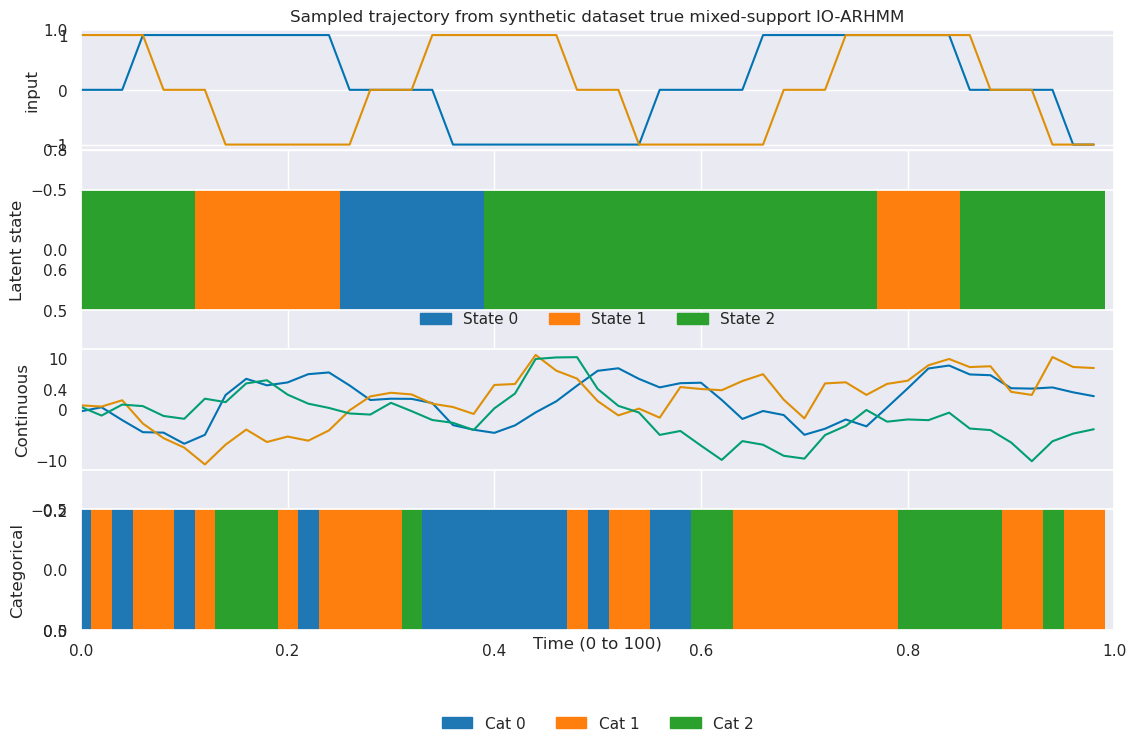

In [10]:
states = np.unique(true_states)
n_states = len(states)

base_cmap = plt.get_cmap("tab10")
colors = [base_cmap(i) for i in range(num_states)]
cmap = ListedColormap(colors)

bounds = np.arange(num_states + 1) - 0.5
norm = BoundaryNorm(bounds, cmap.N)

state_to_idx = {s: i for i, s in enumerate(states)}
true_states_idx = np.vectorize(state_to_idx.get)(true_states)

plt.figure(figsize=(12, 8))
plt.title("Sampled trajectory from synthetic dataset true mixed-support IO-ARHMM")

plt.subplot(411)
plt.plot(inpt)
plt.xticks([])
plt.xlim(0, time_bins)
plt.ylabel("input")

plt.subplot(412)
plt.imshow(
    true_states_idx[None, :],
    aspect="auto",
    cmap=cmap,
    norm=norm
)
plt.xticks([])
plt.xlim(0, time_bins)
plt.ylabel("Latent state")
plt.grid()

legend_patches = [
    mpatches.Patch(color=colors[i], label=f"State {s}")
    for i, s in enumerate(states)
]

plt.legend(
    handles=legend_patches,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.1),
    ncol=n_states,
    frameon=False
)

plt.subplot(413)
plt.plot(obs_flat_cont)
plt.xlim(0, time_bins)
plt.xticks([])
plt.ylabel("Continuous")
plt.grid()


cat_vals = np.unique(obs_flat_cat)
n_cat = len(cat_vals)

# Colormap for categories
cat_colors = [base_cmap(i) for i in range(n_cat)]
cat_cmap = ListedColormap(cat_colors)

cat_bounds = np.arange(n_cat + 1) - 0.5
cat_norm = BoundaryNorm(cat_bounds, cat_cmap.N)

# Map categories to indices
cat_to_idx = {c: i for i, c in enumerate(cat_vals)}
obs_cat_idx = np.vectorize(cat_to_idx.get)(obs_flat_cat)

plt.subplot(414)
plt.imshow(
    obs_cat_idx[None, :],
    aspect="auto",
    cmap=cat_cmap,
    norm=cat_norm,
    interpolation="nearest",
    resample=False
)
plt.xlim(0, time_bins)
plt.ylabel("Categorical")
plt.xticks([])
plt.grid(False)
plt.xlabel("Time (0 to 100)")

# Legend for categorical values
cat_legend_patches = [
    mpatches.Patch(color=cat_colors[i], label=f"Cat {c}")
    for i, c in enumerate(cat_vals)
]

plt.legend(
    handles=cat_legend_patches,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.6),
    ncol=n_cat,
    frameon=False
)


plt.tight_layout()
plt.show()

## Compare w/ learned model

In [69]:
import numpy as np

# Initial state distribution (pi0)
vanilla_pi0 = np.array([0.0058339, 0.03567156, 0.9584945])

# Transition matrix Ps (3 states x 3 states)
vanilla_Ps = np.array([[0.38319856, 0.01128634, 0.60551506],
                       [0.00297652, 0.6757002,  0.32132328],
                       [0.09008587, 0.10714192, 0.80277216]])

# Input weight matrix Ws (3 states x 3 inputs)
vanilla_Ws = np.array([[ 0.98749256,  0.15404467,  0.03359753],
                       [-0.00414018,  0.85617083, -0.51667625],
                       [ 0.875898,   -0.38373232, -0.2924931]])

# AR coefficient matrices As (3 states x 5 features x 5 features)
vanilla_As = np.array([
    [[ 8.7137091e-01, -1.6618092e-01, -1.1256861e-01, -1.8570457e-02, -1.0767156e-02],
     [-2.3250192e-02,  8.7997180e-01,  3.2621812e-02, -1.3891396e-02, -4.3185996e-03],
     [-1.0648817e-01, -3.8029868e-02,  7.4228364e-01, -1.1681180e-02, -3.4966018e-02],
     [-2.0951012e-12,  5.7118342e-12,  4.5394699e-12,  2.0642270e-12,  5.9329559e-13],
     [-2.0853115e-12,  5.5847709e-12,  4.3469252e-12,  1.8580350e-12,  8.2505487e-13]],
    
    [[ 9.1246355e-01,  2.9622167e-02,  3.1023107e-02,  7.5245025e-03, -1.8842429e-03],
     [ 1.0862431e-01,  8.2651114e-01, -4.9856462e-02,  4.1425573e-03, -7.9285546e-04],
     [-5.4491743e-02, -1.5143079e-01,  8.9708799e-01,  2.4040299e-02,  3.1002236e-03],
     [ 2.5592341e-12, -6.3550662e-12, -1.9207385e-12,  9.7526566e-13,  1.2390463e-12],
     [ 2.5512238e-12, -6.6704294e-12, -2.0307738e-12,  7.6545134e-13,  1.4346169e-12]],
    
    [[ 9.1723061e-01, -1.1486311e-03,  3.0137388e-02, -3.5403597e-03,  5.3033407e-04],
     [-8.5936729e-03,  8.8603216e-01, -5.7876009e-02, -8.8030193e-03, -1.8555543e-03],
     [-3.5528488e-02, -1.6381595e-02,  8.8159931e-01,  3.2216702e-03, -5.3994046e-03],
     [-1.1075407e-01, -4.3300870e-01, -2.2900787e-01,  3.9873701e-01, -4.2679003e-01],
     [ 6.2774651e-02,  2.4542637e-01,  1.2980010e-01, -2.2600141e-01,  2.4190168e-01]]
])

# Bias vectors bs (3 states x 5 features)
vanilla_bs = np.array([[ 0.19655402,  0.03409047,  0.00973254, -4.595119,   -4.5849667],
                       [-0.04188687,  0.13514693,  0.22143848, -4.595119,   -4.5849667],
                       [-0.03535473, -0.03998925, -0.03231691,  0.4024005,   1.0490054]])

# Covariance matrices Sigmas (3 states x 5 features x 5 features)
vanilla_Sigmas = np.array([
    [[ 2.4025486e+00,  2.5371328e-01,  1.8956815e-01,  1.7112729e-14,  1.0267638e-14],
     [ 2.5371328e-01,  2.4871516e+00, -2.6771685e-01, -2.8037907e-15, -6.0658842e-15],
     [ 1.8956815e-01, -2.6771685e-01,  2.5184314e+00, -5.6252004e-15, -4.1557893e-15],
     [ 1.7112729e-14, -2.8037907e-15, -5.6252004e-15,  1.0203059e+00,  3.1120553e-12],
     [ 1.0267638e-14, -6.0658842e-15, -4.1557893e-15,  3.1120553e-12,  1.0203059e+00]],
    
    [[ 1.8581796e+00, -5.8836021e-02,  2.2165777e-01,  1.8703290e-15,  2.8054934e-15],
     [-5.8836021e-02,  1.5309291e+00, -6.7651987e-02, -2.1898063e-15,  1.5281345e-14],
     [ 2.2165777e-01, -6.7651987e-02,  2.0251422e+00, -5.5107875e-15,  2.8033157e-15],
     [ 1.8703290e-15, -2.1898063e-15, -5.5107875e-15,  1.0203042e+00,  2.7427336e-27],
     [ 2.8054934e-15,  1.5281345e-14,  2.8033157e-15,  2.7427336e-27,  1.0203042e+00]],
    
    [[ 2.1443620e+00,  1.5747990e-01,  1.8215333e-01, -6.3154322e-01,  3.5795441e-01],
     [ 1.5747990e-01,  2.4396625e+00,  1.4129572e-02,  1.1626950e-01, -6.5900758e-02],
     [ 1.8215333e-01,  1.4129572e-02,  2.4995668e+00, -2.3262696e-01,  1.3185138e-01],
     [-6.3154322e-01,  1.1626950e-01, -2.3262696e-01,  5.2937018e+02, -4.1001728e+01],
     [ 3.5795441e-01, -6.5900758e-02,  1.3185138e-01, -4.1001728e+01,  4.2493529e+00]]
])

In [70]:
vanilla_hmm = ssm.HMM(num_states, obs_dim + cat_dim, input_dim, 
               observations="autoregressive", observation_kwargs=dict(),
               transitions="inputdriven")
vanilla_hmm.transitions.Ws = vanilla_Ws[:, :2] # 3x2
vanilla_hmm.transitions.log_Ps = np.log(vanilla_Ps) + 1 # 3x3
vanilla_hmm.observations.As = vanilla_As # 3x5x5
vanilla_hmm.observations.bs = vanilla_bs # 3x4
vanilla_hmm.observations.Sigmas = vanilla_Sigmas # 3x5x5

#print(pred_hmm.transitions.Ws)
#print(pred_hmm.transitions.log_Ps)
#print(pred_hmm.observations.As)
#print(pred_hmm.observations.bs)
#print(pred_hmm.observations.Sigmas)

In [71]:
import numpy as np

# Initial state distribution (pi0 in logit form)
kd_pi0 = np.array([0.43900168, 0.54963183, 0.01136643])

# Transition matrix Ps (3 states x 3 states)
kd_Ps = np.array([[0.96247137, 0.00866365, 0.02886494],
                   [0.01716947, 0.9415505,  0.04128],
                   [0.11805914, 0.01901711, 0.8629237]])

# Input weight matrix Ws (3 states x 3 inputs)
kd_Ws = np.array([[ 0.5713827,   0.39897093,  0.7171777],
                   [-0.24477547, -0.05749549, -0.9678736],
                   [ 0.34398288,  0.49686348, -0.79674494]])

# AR coefficient matrices As (3 states x 5 features x 5 features)
# Note: These are from the initialization section as final values aren't explicitly printed
kd_As = np.array([
    [[ 9.12317932e-01, -1.40581513e-02, -3.36797349e-03,  1.27610262e-03, -8.47859215e-03],
     [-1.72502827e-02,  8.76617253e-01, -1.78796928e-02, -6.67799357e-03,  1.18372273e-02],
     [-5.52279614e-02, -4.94245179e-02,  8.93116772e-01,  6.08797418e-03,  6.74589537e-03],
     [-1.13461181e-13, -8.34339596e-13, -3.47150314e-13,  2.44086435e-13, -5.74026287e-13],
     [ 2.52030113e-14,  1.89579296e-13,  7.95869718e-14, -5.61097731e-14,  2.44785881e-13]],
    
    [[ 9.10828233e-01, -5.73874218e-03,  6.93517178e-02,  4.58708871e-03, -4.99147549e-03],
     [ 1.83101129e-02,  8.91348898e-01, -1.21178649e-01, -1.86276920e-02, -1.31537933e-02],
     [-3.50557617e-03, -4.09191381e-03,  8.47275555e-01, -5.73396865e-05, -2.20388398e-02],
     [-3.49678104e-13, -5.46116565e-14, -5.77008330e-13,  1.51391822e-12, -1.69054048e-13],
     [ 3.17571246e-13,  1.11110394e-13,  4.49341519e-13, -1.14914252e-12,  2.67809565e-13]],
    
    [[ 9.47774053e-01, -1.58657745e-01, -6.22523651e-02, -7.79222278e-03,  3.47027997e-03],
     [ 4.64824401e-02,  8.80908251e-01, -1.06827319e-02, -1.22189545e-03, -6.31685543e-04],
     [-8.17985833e-02, -7.51991048e-02,  8.80102038e-01,  1.58455204e-02, -1.17322616e-02],
     [ 5.46257680e-14,  4.51377285e-14,  5.29049027e-13,  8.60019575e-13,  5.62802680e-13],
     [ 2.28363318e-14, -1.37138869e-16,  5.06245924e-13,  7.58541775e-13,  6.63412793e-13]]
])

# Bias vectors bs (3 states x 5 features)
kd_bs = np.array([[-0.09000751, -0.02789056, -0.05346639,  3.4760995,  -0.69314617],
                   [ 0.04661614, -0.05281315,  0.01227486, -4.595119,    3.8815653],
                   [ 0.09017603,  0.06995836,  0.0998217,  -4.595119,   -4.5849667]])

# Covariance matrices Sigmas (3 states x 5 features x 5 features)
kd_Sigmas = np.array([
    [[ 3.68717730e-01,  0.00000000e+00,  0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
     [ 8.76676440e-02,  3.98099244e-01,  0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
     [ 1.29015416e-01, -5.06638661e-02,  4.39655840e-01,  0.00000000e+00,  0.00000000e+00],
     [-6.55673064e-16, -1.59251326e-16,  3.11523710e-16,  1.00502064e-02,  0.00000000e+00],
     [-2.04897839e-16,  1.21031863e-16, -9.77640796e-17,  4.81101128e-14,  1.00502064e-02]],
    
    [[ 3.86492729e-01,  0.00000000e+00,  0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
     [ 1.49881855e-01,  4.84404087e-01,  0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
     [ 1.17855921e-01,  4.00683135e-02,  4.58240539e-01,  0.00000000e+00,  0.00000000e+00],
     [-1.10230464e-15,  7.36843913e-16,  2.65560711e-16,  1.00503415e-02,  0.00000000e+00],
     [-4.40921836e-16, -1.27421787e-16, -1.54370881e-16, -1.08518077e-12,  1.00503415e-02]],
    
    [[ 3.78071010e-01,  0.00000000e+00,  0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
     [ 2.72361562e-02,  3.27015430e-01,  0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
     [ 1.34913251e-01, -9.87937227e-02,  4.10525918e-01,  0.00000000e+00,  0.00000000e+00],
     [-1.36771691e-15,  6.43892508e-15,  1.18928137e-15,  1.00502791e-02,  0.00000000e+00],
     [ 5.86164375e-16,  1.75832626e-15,  5.00421824e-16,  1.64642302e-12,  1.00502791e-02]]
])

In [72]:
kd_hmm = ssm.HMM(num_states, obs_dim + cat_dim, input_dim, 
               observations="autoregressive", observation_kwargs=dict(),
               transitions="inputdriven")
kd_hmm.transitions.Ws = kd_Ws[:, :2] # 3x2
kd_hmm.transitions.log_Ps = np.log(kd_Ps) + 1 # 3x3
kd_hmm.observations.As = kd_As # 3x5x5
kd_hmm.observations.bs = kd_bs # 3x4
kd_hmm.observations.Sigmas = kd_Sigmas # 3x5x5

#print(pred_hmm.transitions.Ws)
#print(pred_hmm.transitions.log_Ps)
#print(pred_hmm.observations.As)
#print(pred_hmm.observations.bs)
#print(pred_hmm.observations.Sigmas)

In [73]:
def nuke_axes(ax):
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.set_frame_on(False)

def compare_heatmaps(A, B, title_left, title_right, suptitle, figsize=(8, 4)):
    assert A.shape == B.shape

    vmin = min(A.min(), B.min())
    vmax = max(A.max(), B.max())

    fig, axs = plt.subplots(1, 2, figsize=figsize)

    im0 = axs[0].imshow(A, aspect="auto", vmin=vmin, vmax=vmax)
    axs[0].set_title(title_left)
    nuke_axes(axs[0])
    plt.colorbar(im0, ax=axs[0], fraction=0.046, pad=0.04).outline.set_visible(False)

    im1 = axs[1].imshow(B, aspect="auto", vmin=vmin, vmax=vmax)
    axs[1].set_title(title_right)
    nuke_axes(axs[1])
    plt.colorbar(im1, ax=axs[1], fraction=0.046, pad=0.04).outline.set_visible(False)

    fig.suptitle(suptitle)
    plt.tight_layout()
    plt.show()

def compare_tensor_slices(A, B, name):
    assert A.shape == B.shape
    K = A.shape[0]

    vmin = min(A.min(), B.min())
    vmax = max(A.max(), B.max())

    fig, axs = plt.subplots(K, 2, figsize=(8, 3 * K))

    for k in range(K):
        im0 = axs[k, 0].imshow(A[k], vmin=vmin, vmax=vmax)
        axs[k, 0].set_title(f"True {name}[{k}]")
        nuke_axes(axs[k, 0])
        plt.colorbar(im0, ax=axs[k, 0], fraction=0.046, pad=0.04).outline.set_visible(False)

        im1 = axs[k, 1].imshow(B[k], vmin=vmin, vmax=vmax)
        axs[k, 1].set_title(f"Learned {name}[{k}]")
        nuke_axes(axs[k, 1])
        plt.colorbar(im1, ax=axs[k, 1], fraction=0.046, pad=0.04).outline.set_visible(False)

    fig.suptitle(f"{name} comparison")
    plt.tight_layout()
    plt.show()

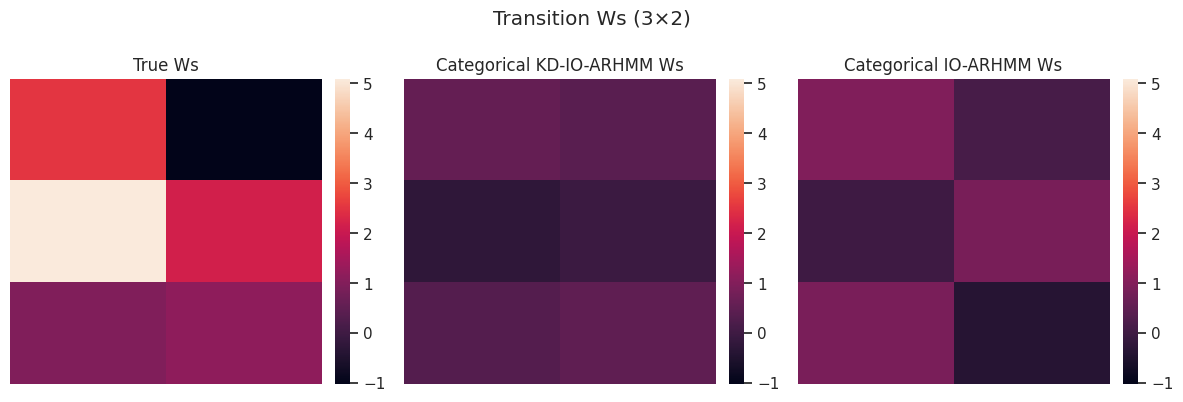

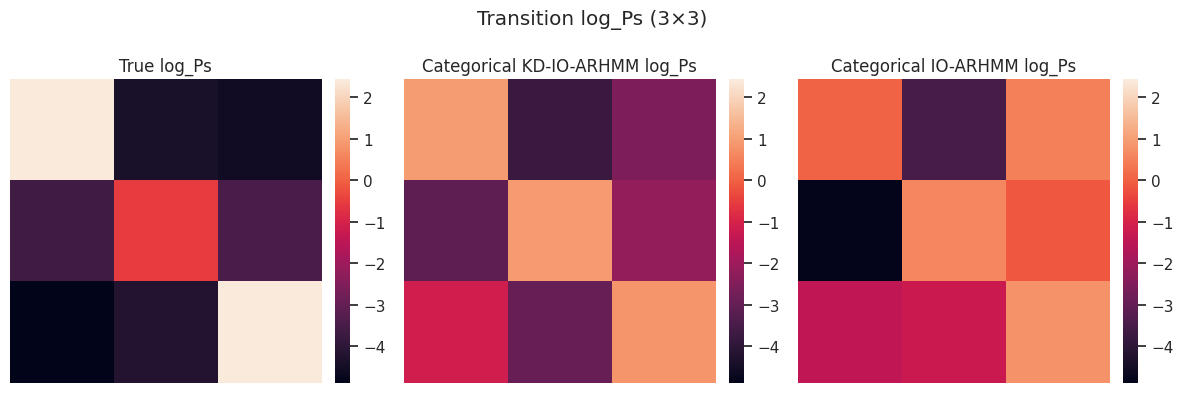

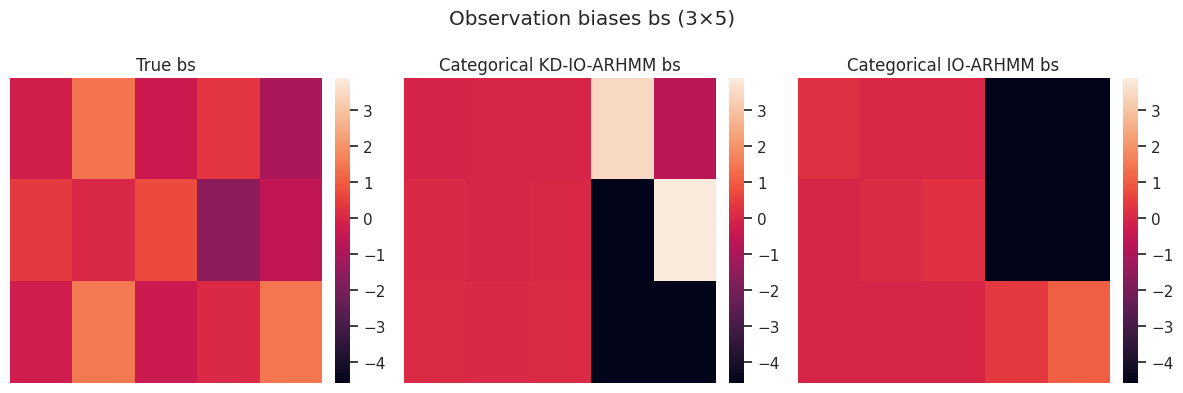

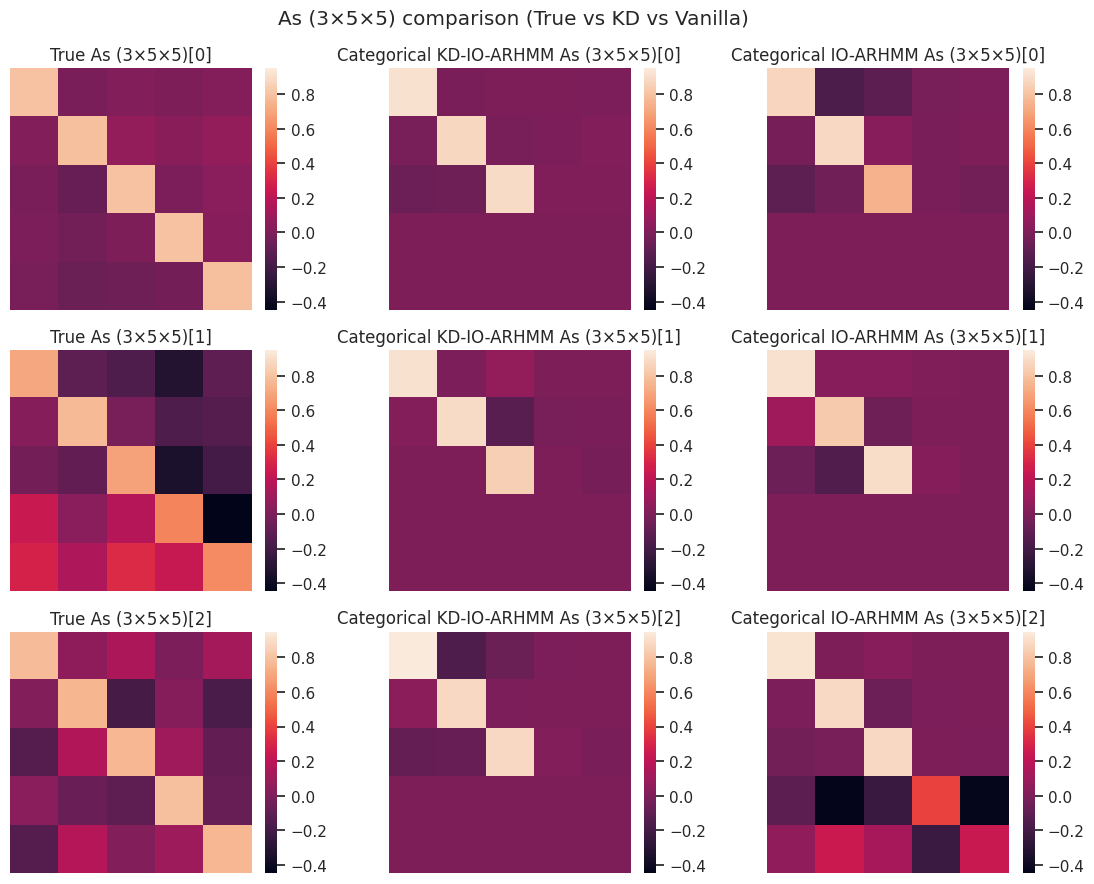

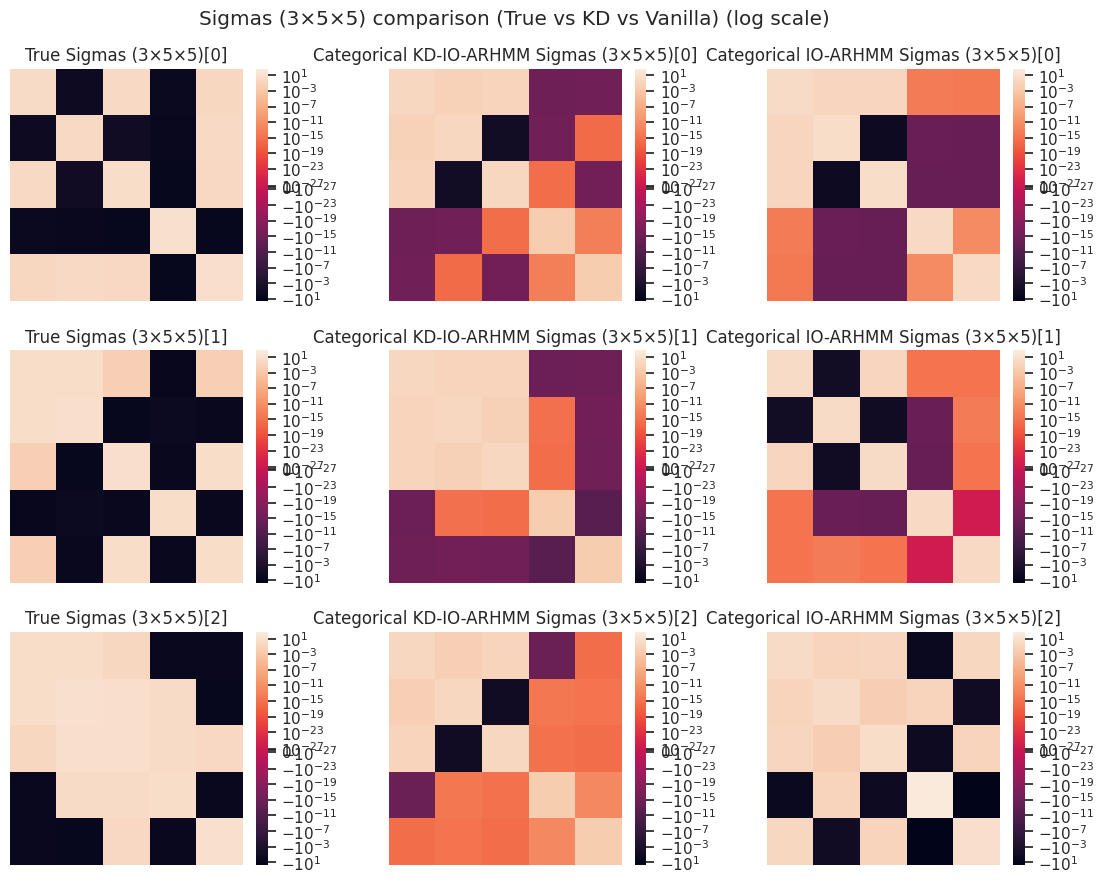

In [140]:
def compare_heatmaps_3(A, B, C, title_left, title_mid, title_right, suptitle, figsize=(12, 4)):
    """Compare three heatmaps side by side."""
    assert A.shape == B.shape == C.shape

    vmin = min(A.min(), B.min(), C.min())
    vmax = max(A.max(), B.max(), C.max())

    fig, axs = plt.subplots(1, 3, figsize=figsize)

    im0 = axs[0].imshow(A, aspect="auto", vmin=vmin, vmax=vmax)
    axs[0].set_title(title_left)
    nuke_axes(axs[0])
    plt.colorbar(im0, ax=axs[0], fraction=0.046, pad=0.04).outline.set_visible(False)

    im1 = axs[1].imshow(B, aspect="auto", vmin=vmin, vmax=vmax)
    axs[1].set_title(title_mid)
    nuke_axes(axs[1])
    plt.colorbar(im1, ax=axs[1], fraction=0.046, pad=0.04).outline.set_visible(False)

    im2 = axs[2].imshow(C, aspect="auto", vmin=vmin, vmax=vmax)
    axs[2].set_title(title_right)
    nuke_axes(axs[2])
    plt.colorbar(im2, ax=axs[2], fraction=0.046, pad=0.04).outline.set_visible(False)

    fig.suptitle(suptitle)
    plt.tight_layout()
    plt.show()

def compare_tensor_slices_3(A, B, C, name, titles=("True", "Categorical KD-IO-ARHMM", "Categorical IO-ARHMM"), log_scale=False):
    """Compare three tensors slice by slice.
    
    Args:
        A, B, C: Tensors to compare (same shape)
        name: Name for the plot title
        titles: Tuple of titles for each tensor
        log_scale: If True, use symmetric log scale for visualization
    """
    from matplotlib.colors import SymLogNorm
    
    assert A.shape == B.shape == C.shape
    K = A.shape[0]

    vmin = min(A.min(), B.min(), C.min())
    vmax = max(A.max(), B.max(), C.max())
    
    # For log scale, use symmetric log norm to handle negative values
    if log_scale:
        # Use the smallest non-zero absolute value as linthresh
        all_vals = np.concatenate([np.abs(A.flatten()), np.abs(B.flatten()), np.abs(C.flatten())])
        linthresh = np.min(all_vals[all_vals > 0]) if np.any(all_vals > 0) else 1e-10
        norm = SymLogNorm(linthresh=linthresh, vmin=vmin, vmax=vmax)
    else:
        norm = None

    fig, axs = plt.subplots(K, 3, figsize=(12, 3 * K))

    for k in range(K):
        if log_scale:
            im0 = axs[k, 0].imshow(A[k], norm=norm)
        else:
            im0 = axs[k, 0].imshow(A[k], vmin=vmin, vmax=vmax)
        axs[k, 0].set_title(f"{titles[0]} {name}[{k}]")
        nuke_axes(axs[k, 0])
        plt.colorbar(im0, ax=axs[k, 0], fraction=0.046, pad=0.04).outline.set_visible(False)

        if log_scale:
            im1 = axs[k, 1].imshow(B[k], norm=norm)
        else:
            im1 = axs[k, 1].imshow(B[k], vmin=vmin, vmax=vmax)
        axs[k, 1].set_title(f"{titles[1]} {name}[{k}]")
        nuke_axes(axs[k, 1])
        plt.colorbar(im1, ax=axs[k, 1], fraction=0.046, pad=0.04).outline.set_visible(False)

        if log_scale:
            im2 = axs[k, 2].imshow(C[k], norm=norm)
        else:
            im2 = axs[k, 2].imshow(C[k], vmin=vmin, vmax=vmax)
        axs[k, 2].set_title(f"{titles[2]} {name}[{k}]")
        nuke_axes(axs[k, 2])
        plt.colorbar(im2, ax=axs[k, 2], fraction=0.046, pad=0.04).outline.set_visible(False)

    scale_str = " (log scale)" if log_scale else ""
    fig.suptitle(f"{name} comparison (True vs KD vs Vanilla){scale_str}")
    plt.tight_layout()
    plt.show()

# Define the three HMMs to compare
hmm_true = true_hmm
hmm_kd = kd_hmm
hmm_vanilla = vanilla_hmm

# Compare Transition Ws (3×2)
compare_heatmaps_3(
    hmm_true.transitions.Ws,
    hmm_kd.transitions.Ws,
    hmm_vanilla.transitions.Ws,
    "True Ws",
    "Categorical KD-IO-ARHMM Ws",
    "Categorical IO-ARHMM Ws",
    "Transition Ws (3×2)"
)

# Compare Transition log_Ps (3×3)
compare_heatmaps_3(
    hmm_true.transitions.log_Ps,
    hmm_kd.transitions.log_Ps,
    hmm_vanilla.transitions.log_Ps,
    "True log_Ps",
    "Categorical KD-IO-ARHMM log_Ps",
    "Categorical IO-ARHMM log_Ps",
    "Transition log_Ps (3×3)"
)

# Compare Observation biases bs (3×5)
compare_heatmaps_3(
    hmm_true.observations.bs,
    hmm_kd.observations.bs,
    hmm_vanilla.observations.bs,
    "True bs",
    "Categorical KD-IO-ARHMM bs",
    "Categorical IO-ARHMM bs",
    "Observation biases bs (3×5)"
)

# Compare Autoregressive coefficients As (3×5×5)
compare_tensor_slices_3(
    hmm_true.observations.As,
    hmm_kd.observations.As,
    hmm_vanilla.observations.As,
    "As (3×5×5)"
)

# Compare Observation covariances Sigmas (3×5×5) - use log scale due to large value ranges
compare_tensor_slices_3(
    hmm_true.observations.Sigmas,
    hmm_kd.observations.Sigmas,
    hmm_vanilla.observations.Sigmas,
    "Sigmas (3×5×5)",
    log_scale=True
)

VITERBI DECODING ON TRUE HMM OBSERVATIONS
Observation shape: (100, 5)
Input shape: (100, 2)

KD HMM Viterbi Accuracy:      0.5800 (58/100 timesteps)
Vanilla HMM Viterbi Accuracy: 0.6600 (66/100 timesteps)



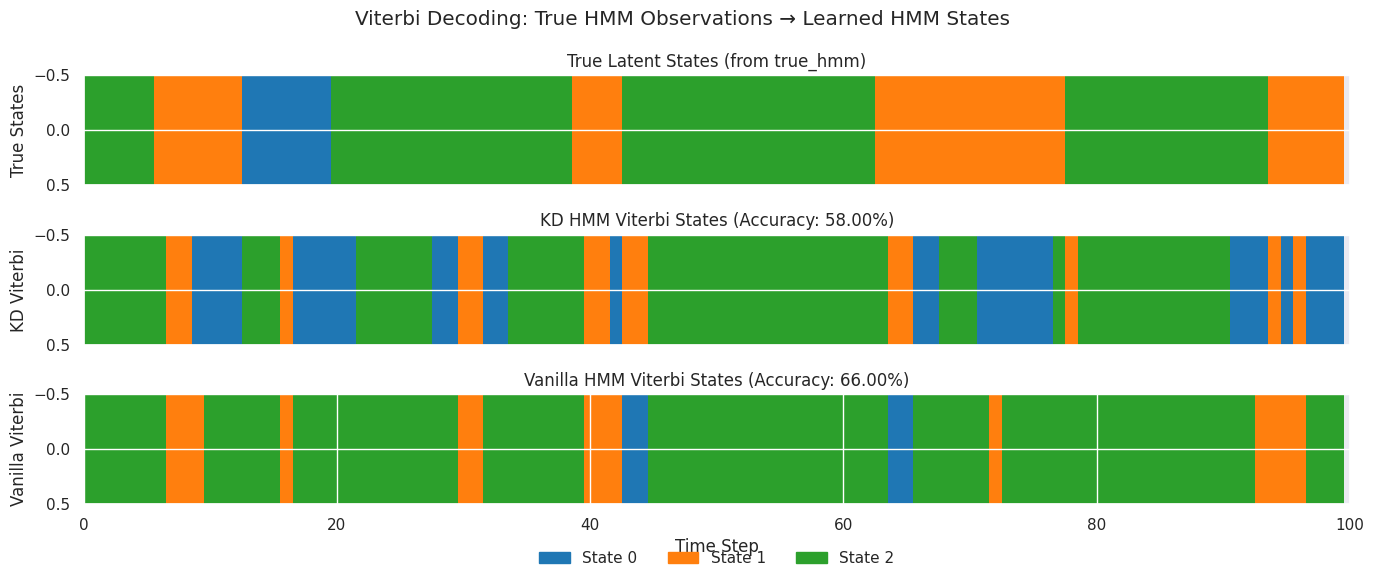

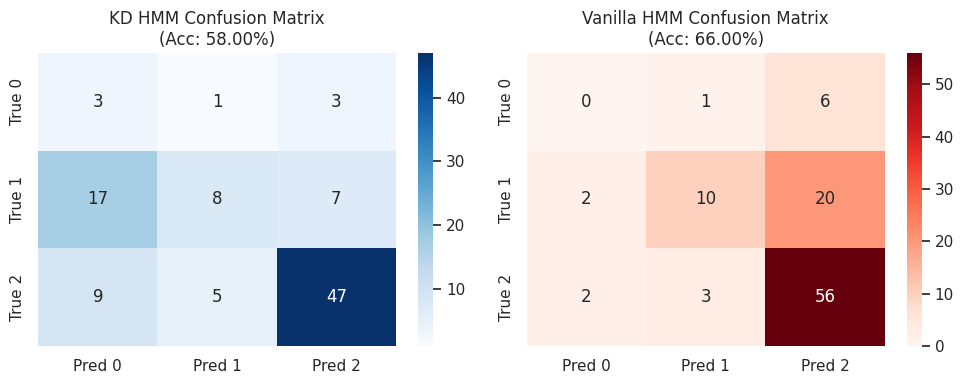

In [75]:
# Apply Viterbi decoding to find most-likely latent states for true_hmm observations using kd_hmm
# obs: observation trajectory from true_hmm
# inpt: exogenous input used during sampling

# Get the most likely states using Viterbi algorithm on kd_hmm
kd_viterbi_states = np.choose(kd_hmm.most_likely_states(obs, input=inpt), [0, 2, 1])

# Also get Viterbi states from vanilla_hmm for comparison
vanilla_viterbi_states = np.choose(vanilla_hmm.most_likely_states(obs, input=inpt), [1, 0, 2])

# Compare with true states
print("=" * 60)
print("VITERBI DECODING ON TRUE HMM OBSERVATIONS")
print("=" * 60)
print(f"Observation shape: {obs.shape}")
print(f"Input shape: {inpt.shape}")
print()

# Calculate accuracy
kd_accuracy = np.mean(kd_viterbi_states == true_states)
vanilla_accuracy = np.mean(vanilla_viterbi_states == true_states)

print(f"KD HMM Viterbi Accuracy:      {kd_accuracy:.4f} ({np.sum(kd_viterbi_states == true_states)}/{len(true_states)} timesteps)")
print(f"Vanilla HMM Viterbi Accuracy: {vanilla_accuracy:.4f} ({np.sum(vanilla_viterbi_states == true_states)}/{len(true_states)} timesteps)")
print()

# Setup colormap for ALL states (same style as other plots)
from matplotlib.colors import ListedColormap, BoundaryNorm
import matplotlib.patches as mpatches

base_cmap = plt.get_cmap("tab10")
colors = [base_cmap(i) for i in range(num_states)]
cmap = ListedColormap(colors)

bounds = np.arange(num_states + 1) - 0.5
norm = BoundaryNorm(bounds, cmap.N)

# Plot the state sequences using imshow (same style as other plots)
# Use raw state values directly (0, 1, 2, ...) without mapping
plt.figure(figsize=(14, 6))
plt.suptitle("Viterbi Decoding: True HMM Observations → Learned HMM States")

plt.subplot(311)
plt.imshow(
    true_states[None, :],
    aspect="auto",
    cmap=cmap,
    norm=norm
)
plt.xlim(0, time_bins)
plt.xticks([])
plt.ylabel("True States")
plt.title("True Latent States (from true_hmm)")

plt.subplot(312)
plt.imshow(
    kd_viterbi_states[None, :],
    aspect="auto",
    cmap=cmap,
    norm=norm
)
plt.xlim(0, time_bins)
plt.xticks([])
plt.ylabel("KD Viterbi")
plt.title(f"KD HMM Viterbi States (Accuracy: {kd_accuracy:.2%})")

plt.subplot(313)
plt.imshow(
    vanilla_viterbi_states[None, :],
    aspect="auto",
    cmap=cmap,
    norm=norm
)
plt.xlim(0, time_bins)
plt.ylabel("Vanilla Viterbi")
plt.title(f"Vanilla HMM Viterbi States (Accuracy: {vanilla_accuracy:.2%})")
plt.xlabel("Time Step")

# Add legend for ALL states (0 to num_states-1)
legend_patches = [
    mpatches.Patch(color=colors[i], label=f"State {i}")
    for i in range(num_states)
]
plt.legend(
    handles=legend_patches,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.3),
    ncol=num_states,
    frameon=False
)

plt.tight_layout()
plt.show()

# Show confusion matrices
from sklearn.metrics import confusion_matrix
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

cm_kd = confusion_matrix(true_states, kd_viterbi_states, labels=range(num_states))
sns.heatmap(cm_kd, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=[f'Pred {i}' for i in range(num_states)],
            yticklabels=[f'True {i}' for i in range(num_states)])
axes[0].set_title(f'KD HMM Confusion Matrix\n(Acc: {kd_accuracy:.2%})')

cm_vanilla = confusion_matrix(true_states, vanilla_viterbi_states, labels=range(num_states))
sns.heatmap(cm_vanilla, annot=True, fmt='d', cmap='Reds', ax=axes[1],
            xticklabels=[f'Pred {i}' for i in range(num_states)],
            yticklabels=[f'True {i}' for i in range(num_states)])
axes[1].set_title(f'Vanilla HMM Confusion Matrix\n(Acc: {vanilla_accuracy:.2%})')

plt.tight_layout()
plt.show()

In [76]:
inpt = np.hstack([np.round(np.sin(2 * np.pi * np.arange(time_bins)/30)[:, None]), np.round(np.cos(2 * np.pi * np.arange(time_bins)/20)[:, None])])
# Sample some data from the HMM
kd_states, kd_obs = kd_hmm.sample(time_bins, input=inpt)

# Compute the true log probability of the data, summing out the discrete states
kd_lp = kd_hmm.log_probability(kd_obs, inputs=inpt)

# Apply stick-breaking on last cat_dim observation variables
kd_obs_flat_cont = np.array([x for x in kd_obs[:, :-cat_dim]])
kd_obs_flat_cat = np.array([x for x in cont_to_cat(kd_obs[:, -cat_dim:])[:, np.newaxis]])

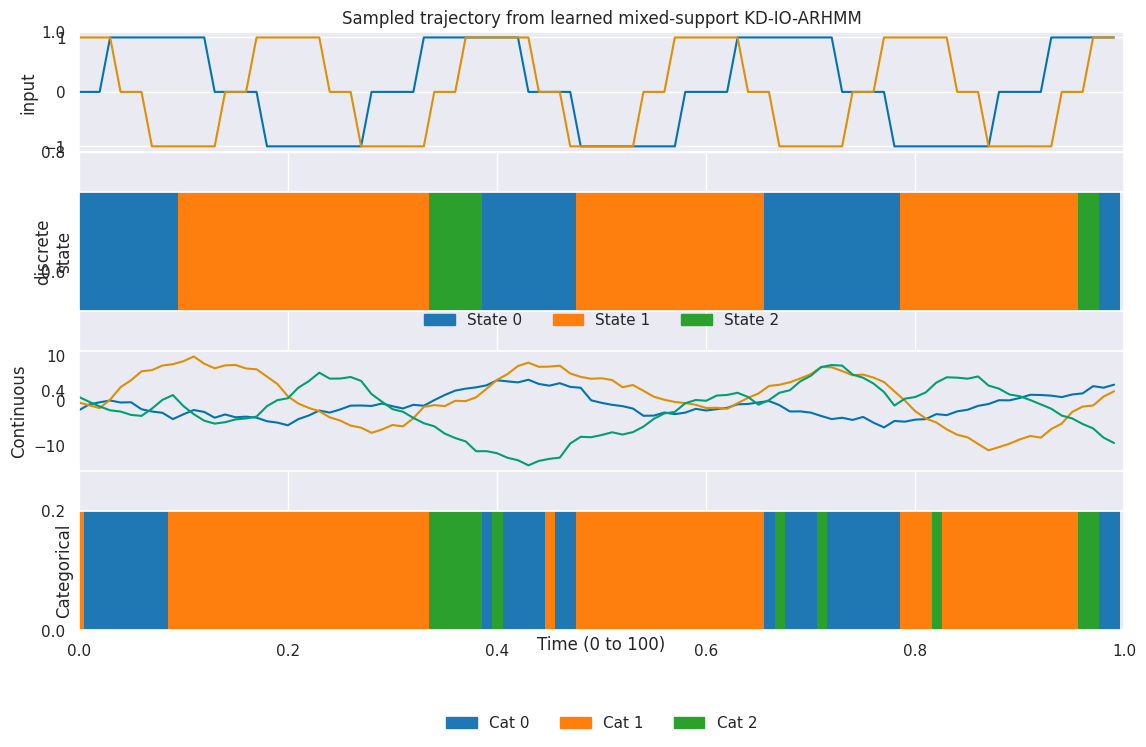

In [88]:
states = np.unique(kd_states)
n_states = len(states)

base_cmap = plt.get_cmap("tab10")
colors = [base_cmap(i) for i in range(num_states)]
cmap = ListedColormap(colors)

bounds = np.arange(num_states + 1) - 0.5
norm = BoundaryNorm(bounds, cmap.N)

state_to_idx = {s: i for i, s in enumerate(states)}
true_states_idx = np.vectorize(state_to_idx.get)(kd_states)

plt.figure(figsize=(12, 8))
plt.title("Sampled trajectory from learned mixed-support KD-IO-ARHMM")

plt.subplot(411)
plt.plot(inpt)
plt.xticks([])
plt.xlim(0, time_bins)
plt.ylabel("input")

plt.subplot(412)
plt.imshow(
    true_states_idx[None, :],
    aspect="auto",
    cmap=cmap,
    norm=norm
)
plt.xticks([])
plt.xlim(0, time_bins)
plt.ylabel("discrete\nstate")
plt.yticks([])

legend_patches = [
    mpatches.Patch(color=colors[i], label=f"State {s}")
    for i, s in enumerate(states)
]

plt.legend(
    handles=legend_patches,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.1),
    ncol=n_states,
    frameon=False
)

plt.subplot(413)
plt.plot(kd_obs_flat_cont)
plt.xlim(0, time_bins)
plt.xticks([])
plt.ylabel("Continuous")
plt.grid()


cat_vals = np.unique(kd_obs_flat_cat)
n_cat = len(cat_vals)

# Colormap for categories
cat_colors = [base_cmap(i) for i in range(n_cat)]
cat_cmap = ListedColormap(cat_colors)

cat_bounds = np.arange(n_cat + 1) - 0.5
cat_norm = BoundaryNorm(cat_bounds, cat_cmap.N)

# Map categories to indices
cat_to_idx = {c: i for i, c in enumerate(cat_vals)}
obs_cat_idx = np.vectorize(cat_to_idx.get)(kd_obs_flat_cat)

plt.subplot(414)
plt.imshow(
    obs_cat_idx[None, :],
    aspect="auto",
    cmap=cat_cmap,
    norm=cat_norm,
    interpolation="nearest",
    resample=False
)
plt.xlim(0, time_bins)
plt.ylabel("Categorical")
plt.yticks([])
plt.xticks([])
plt.grid(False)
plt.xlabel("Time (0 to 100)")

# Legend for categorical values
cat_legend_patches = [
    mpatches.Patch(color=cat_colors[i], label=f"Cat {c}")
    for i, c in enumerate(cat_vals)
]

plt.legend(
    handles=cat_legend_patches,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.6),
    ncol=n_cat,
    frameon=False
)


plt.tight_layout()
plt.show()

In [78]:
inpt = np.hstack([np.round(np.sin(2 * np.pi * np.arange(time_bins)/30)[:, None]), np.round(np.cos(2 * np.pi * np.arange(time_bins)/20)[:, None])])
# Sample some data from the HMM
vanilla_states, vanilla_obs = vanilla_hmm.sample(time_bins, input=inpt)

# Compute the true log probability of the data, summing out the discrete states
vanilla_lp = vanilla_hmm.log_probability(vanilla_obs, inputs=inpt)

# Apply stick-breaking on last cat_dim observation variables
vanilla_obs_flat_cont = np.array([x for x in vanilla_obs[:, :-cat_dim]])
vanilla_obs_flat_cat = np.array([x for x in cont_to_cat(vanilla_obs[:, -cat_dim:])[:, np.newaxis]])

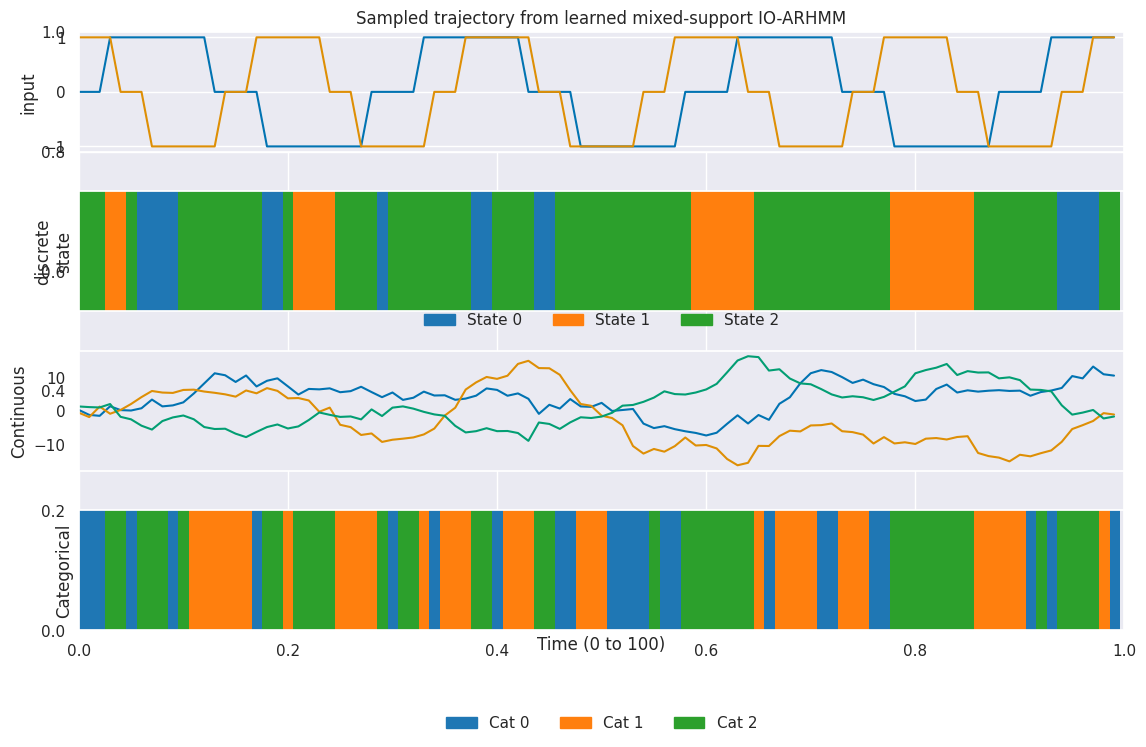

In [79]:
states = np.unique(vanilla_states)
n_states = len(states)

base_cmap = plt.get_cmap("tab10")
colors = [base_cmap(i) for i in range(num_states)]
cmap = ListedColormap(colors)

bounds = np.arange(num_states + 1) - 0.5
norm = BoundaryNorm(bounds, cmap.N)

state_to_idx = {s: i for i, s in enumerate(states)}
true_states_idx = np.vectorize(state_to_idx.get)(vanilla_states)

plt.figure(figsize=(12, 8))
plt.title("Sampled trajectory from learned mixed-support IO-ARHMM")

plt.subplot(411)
plt.plot(inpt)
plt.xticks([])
plt.xlim(0, time_bins)
plt.ylabel("input")

plt.subplot(412)
plt.imshow(
    true_states_idx[None, :],
    aspect="auto",
    cmap=cmap,
    norm=norm
)
plt.xticks([])
plt.xlim(0, time_bins)
plt.ylabel("discrete\nstate")
plt.yticks([])

legend_patches = [
    mpatches.Patch(color=colors[i], label=f"State {s}")
    for i, s in enumerate(states)
]

plt.legend(
    handles=legend_patches,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.1),
    ncol=n_states,
    frameon=False
)

plt.subplot(413)
plt.plot(vanilla_obs_flat_cont)
plt.xlim(0, time_bins)
plt.xticks([])
plt.ylabel("Continuous")
plt.grid()


cat_vals = np.unique(vanilla_obs_flat_cat)
n_cat = len(cat_vals)

# Colormap for categories
cat_colors = [base_cmap(i) for i in range(n_cat)]
cat_cmap = ListedColormap(cat_colors)

cat_bounds = np.arange(n_cat + 1) - 0.5
cat_norm = BoundaryNorm(cat_bounds, cat_cmap.N)

# Map categories to indices
cat_to_idx = {c: i for i, c in enumerate(cat_vals)}
obs_cat_idx = np.vectorize(cat_to_idx.get)(vanilla_obs_flat_cat)

plt.subplot(414)
plt.imshow(
    obs_cat_idx[None, :],
    aspect="auto",
    cmap=cat_cmap,
    norm=cat_norm,
    interpolation="nearest",
    resample=False
)
plt.xlim(0, time_bins)
plt.ylabel("Categorical")
plt.yticks([])
plt.xticks([])
plt.grid(False)
plt.xlabel("Time (0 to 100)")

# Legend for categorical values
cat_legend_patches = [
    mpatches.Patch(color=cat_colors[i], label=f"Cat {c}")
    for i, c in enumerate(cat_vals)
]

plt.legend(
    handles=cat_legend_patches,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.6),
    ncol=n_cat,
    frameon=False
)


plt.tight_layout()
plt.show()

## Synthetic dataset generation

In [11]:
import pandas as pd
import os
from tqdm import tqdm

# Configuration
output_dir = "synthetic_data_files"
os.makedirs(output_dir, exist_ok=True)

# Parameters for patient generation
T = time_bins  # number of time bins per patient (use same as time_bins from HMM)
num_patients = 2000  # number of patients to generate

# Generate independent data for each patient
print(f"Generating {num_patients} patients with {T} time bins each...")
obs_full_list = []  # NEW: Save full observations with stick-breaking representation
obs_cont_list = []
obs_cat_list = []
inpt_list = []
states_list = []

for patient_idx in range(num_patients):
    # Create an exogenous input for this patient (same pattern as before)
    patient_inpt = np.hstack([
        np.round(np.sin(2 * np.pi * np.arange(T)/150)[:, None]) + 1e-1 * npr.randn(T, 1),
        np.round(np.cos(2 * np.pi * np.arange(T)/100)[:, None]) + 1e-1 * npr.randn(T, 1)
    ])
    
    # Sample new data from the HMM for this patient
    patient_states, patient_obs = true_hmm.sample(T, input=patient_inpt)
    
    # Apply stick-breaking on last cat_dim observation variables
    patient_obs_cont = patient_obs[:, :-cat_dim]
    patient_obs_cat = cont_to_cat(patient_obs[:, -cat_dim:])[:, np.newaxis]
    
    obs_full_list.append(patient_obs)  # NEW: Save full observations
    obs_cont_list.append(patient_obs_cont)
    obs_cat_list.append(patient_obs_cat)
    inpt_list.append(patient_inpt)
    states_list.append(patient_states)

# Stack into arrays with shape (num_patients, T, features)
obs_full_reshaped = np.stack(obs_full_list)  # NEW: (num_patients, T, obs_dim + cat_dim)
obs_cont_reshaped = np.stack(obs_cont_list)  # (num_patients, T, obs_dim)
obs_cat_reshaped = np.stack(obs_cat_list)    # (num_patients, T, 1)
inpt_reshaped = np.stack(inpt_list)          # (num_patients, T, input_dim)
states_reshaped = np.stack(states_list)      # (num_patients, T)

print(f"Generated data shapes:")
print(f"  - obs_full: {obs_full_reshaped.shape}  (FULL observations with stick-breaking)")
print(f"  - obs_cont: {obs_cont_reshaped.shape}")
print(f"  - obs_cat: {obs_cat_reshaped.shape}")
print(f"  - inputs: {inpt_reshaped.shape}")
print(f"  - states: {states_reshaped.shape}")

# Generate feature names
cont_feature_names = [f"cont_feat_{i}" for i in range(obs_dim)]
cat_feature_name = "cat_feat"
input_feature_names = [f"input_{i}" for i in range(input_dim)]

# ============================================
# 1. Generate Main Data File (data_file)
# ============================================
data_rows = []
for patient_idx in range(num_patients):
    stay_id = 30000000 + patient_idx  # Unique stay ID
    for hour in range(T):
        row = {
            'stay_id': stay_id,
            'hour': hour,
            'gender': 1,  # Dummy gender (required for filtering)
        }
        # Add continuous features
        for feat_idx, feat_name in enumerate(cont_feature_names):
            row[feat_name] = obs_cont_reshaped[patient_idx, hour, feat_idx]
        # Add categorical feature
        row[cat_feature_name] = int(obs_cat_reshaped[patient_idx, hour, 0])
        # Add input features (optional, can be used as inputs to the model)
        for inp_idx, inp_name in enumerate(input_feature_names):
            row[inp_name] = inpt_reshaped[patient_idx, hour, inp_idx]
        # Add careunit indicator columns (all zeros except one)
        for careunit in ['MICU', 'TSICU', 'MSICU', 'NSICU', 'CCU', 'NIU', 'SICU', 'CVICU', 'NSU', 'PACU']:
            row[careunit] = 1 if careunit == 'MICU' else 0
        # Add true state (for debugging/analysis)
        row['true_state'] = states_reshaped[patient_idx, hour]
        data_rows.append(row)

data_df = pd.DataFrame(data_rows)
data_file_path = os.path.join(output_dir, "synthetic_data.csv")
data_df.to_csv(data_file_path, index=True)
print(f"Generated data file: {data_file_path}")
print(f"  - {num_patients} patients, {T} time bins each")
print(f"  - Columns: {list(data_df.columns)}")

# ============================================
# 2. Generate Label/Outcomes File (label_file)
# ============================================
# Generate labels BASED ON HMM STATES - this is critical for the model to learn meaningful parameters!
# Patients who spend more time in state 0 (high variance state) have higher mortality
np.random.seed(42)  # For reproducibility

# Calculate fraction of time each patient spends in each state
state_fractions = np.zeros((num_patients, num_states))
for patient_idx in range(num_patients):
    patient_states = states_reshaped[patient_idx]
    for state in range(num_states):
        state_fractions[patient_idx, state] = np.mean(patient_states == state)

# DETERMINISTIC mortality based on dominant state
# With extremely sticky states, patients should be 100% in one state
# If dominant state is 0 → 100% death, if dominant state is 2 → 0% death
state_mortality_probs = np.array([1.0, 0.5, 0.0])  # Keep same for compatibility

# Compute death probability for each patient as weighted average of time in each state
death_probs = state_fractions @ state_mortality_probs

# MODIFIED: Use deterministic threshold instead of sampling
# If patient spends >50% time in state 0, they die with 100% certainty
# If patient spends >50% time in state 2, they survive with 100% certainty
death_labels = np.zeros(num_patients, dtype=int)
for patient_idx in range(num_patients):
    if state_fractions[patient_idx, 0] > 0.5:  # Dominant state 0
        death_labels[patient_idx] = 1  # Dies
    elif state_fractions[patient_idx, 2] > 0.5:  # Dominant state 2
        death_labels[patient_idx] = 0  # Survives
    else:  # Edge case: no dominant state (should be rare with sticky states)
        # Fall back to probabilistic
        death_labels[patient_idx] = int(np.random.rand() < death_probs[patient_idx])

print(f"State-based label generation:")
print(f"  - State mortality probabilities: {state_mortality_probs}")
print(f"  - State 0 (latent state 1): {state_mortality_probs[0]*100:.0f}% mortality")
print(f"  - State 1 (latent state 2): {state_mortality_probs[1]*100:.0f}% mortality")
print(f"  - State 2 (latent state 3): {state_mortality_probs[2]*100:.0f}% mortality")
print(f"  - Mean death probability: {death_probs.mean():.3f}")
print(f"  - Actual mortality rate: {death_labels.mean():.3f}")

# DIAGNOSTIC: Check if modified dynamics created COMPLETE separation
print("\n" + "=" * 70)
print("DIAGNOSTIC: COMPLETE State Separation Check")
print("=" * 70)
alive_mask = death_labels == 0
dead_mask = death_labels == 1
alive_fracs = state_fractions[alive_mask]
dead_fracs = state_fractions[dead_mask]

print(f"\nAlive patients (n={alive_mask.sum()}):")
print(f"  Mean state fractions: State 0: {alive_fracs[:, 0].mean():.4f}, State 1: {alive_fracs[:, 1].mean():.4f}, State 2: {alive_fracs[:, 2].mean():.4f}")
print(f"  Std state fractions:  State 0: {alive_fracs[:, 0].std():.4f}, State 1: {alive_fracs[:, 1].std():.4f}, State 2: {alive_fracs[:, 2].std():.4f}")
print(f"  Min/Max state 0: [{alive_fracs[:, 0].min():.4f}, {alive_fracs[:, 0].max():.4f}]")
print(f"  Min/Max state 2: [{alive_fracs[:, 2].min():.4f}, {alive_fracs[:, 2].max():.4f}]")

print(f"\nDead patients (n={dead_mask.sum()}):")
print(f"  Mean state fractions: State 0: {dead_fracs[:, 0].mean():.4f}, State 1: {dead_fracs[:, 1].mean():.4f}, State 2: {dead_fracs[:, 2].mean():.4f}")
print(f"  Std state fractions:  State 0: {dead_fracs[:, 0].std():.4f}, State 1: {dead_fracs[:, 1].std():.4f}, State 2: {dead_fracs[:, 2].std():.4f}")
print(f"  Min/Max state 0: [{dead_fracs[:, 0].min():.4f}, {dead_fracs[:, 0].max():.4f}]")
print(f"  Min/Max state 2: [{dead_fracs[:, 2].min():.4f}, {dead_fracs[:, 2].max():.4f}]")

print(f"\nDifference (Dead - Alive):")
for s in range(num_states):
    diff = dead_fracs[:, s].mean() - alive_fracs[:, s].mean()
    if alive_fracs[:, s].std() > 1e-6:
        effect_size = diff / alive_fracs[:, s].std()
    else:
        effect_size = float('inf') if abs(diff) > 1e-6 else 0
    print(f"  State {s}: {diff:+.4f} (effect size: {effect_size:.2f} std)")

print(f"\nState dominance (patients spending >90% time in one state):")
for s in range(num_states):
    alive_dominant = (alive_fracs[:, s] > 0.9).sum()
    dead_dominant = (dead_fracs[:, s] > 0.9).sum()
    print(f"  State {s} dominant (>90%): {alive_dominant} alive ({100*alive_dominant/alive_mask.sum():.1f}%), {dead_dominant} dead ({100*dead_dominant/dead_mask.sum():.1f}%)")

# Check for complete separation (non-overlapping distributions)
state0_overlap = (alive_fracs[:, 0].max() >= dead_fracs[:, 0].min())
state2_overlap = (dead_fracs[:, 2].max() >= alive_fracs[:, 2].min())

print(f"\nOverlap Analysis:")
print(f"  State 0 (high mortality): {'OVERLAP' if state0_overlap else 'NO OVERLAP (PERFECT SEPARATION)'}")
print(f"    Alive max: {alive_fracs[:, 0].max():.4f}, Dead min: {dead_fracs[:, 0].min():.4f}")
print(f"  State 2 (low mortality): {'OVERLAP' if state2_overlap else 'NO OVERLAP (PERFECT SEPARATION)'}")
print(f"    Dead max: {dead_fracs[:, 2].max():.4f}, Alive min: {alive_fracs[:, 2].min():.4f}")

print("=" * 70)
if not state0_overlap and not state2_overlap:
    print("✓ COMPLETE SEPARATION ACHIEVED!")
    print("  Dead patients have ZERO overlap with alive in state distributions")
    print("  This creates a perfectly learnable classification task")
else:
    print("✗ INCOMPLETE SEPARATION - distributions still overlap")
    print("  Need stronger dynamics or different parameter settings")
print("=" * 70)

label_rows = []
for patient_idx in tqdm(range(num_patients)):
    stay_id = 30000000 + patient_idx
    death_val = int(death_labels[patient_idx])
    label_rows.append({
        'stay_id': stay_id,
        'death': death_val,
        'died_in_hosp': death_val,
        'died_within_48h_of_out_time': death_val,
        'mortality_90d': death_val,
    })

label_df = pd.DataFrame(label_rows)
label_file_path = os.path.join(output_dir, "synthetic_outcomes.csv")
label_df.to_csv(label_file_path, index=False)
num_deaths = death_labels.sum()
print(f"\nGenerated label file: {label_file_path}")
print(f"  - {num_patients} patients total: {num_deaths} deaths ({100*num_deaths/num_patients:.1f}%), {num_patients - num_deaths} survivors")

# ============================================
# 3. Generate Careunit File (careunit_file)
# ============================================
# Assume all patients are from the same careunit (MICU)
careunit_rows = []
for patient_idx in range(num_patients):
    stay_id = 30000000 + patient_idx
    for hour in range(T):
        careunit_rows.append({
            'stay_id': stay_id,
            'first_careunit': 'MICU',  # All patients from MICU
        })

careunit_df = pd.DataFrame(careunit_rows)
careunit_file_path = os.path.join(output_dir, "synthetic_careunit.csv")
careunit_df.to_csv(careunit_file_path, index=True)
print(f"\nGenerated careunit file: {careunit_file_path}")
print(f"  - All patients assigned to MICU careunit")

# ============================================
# 4. Generate Feature Preprocessing Information File
# ============================================
preprocessing_rows = []

# Continuous features - all normal distribution
for feat_name in cont_feature_names:
    feat_data = data_df[feat_name]
    preprocessing_rows.append({
        'feature': feat_name,
        'Teacher Model Only': False,
        'distribution': 'normal',
        'min_bound': feat_data.min() - 3 * feat_data.std(),
        'max_bound': feat_data.max() + 3 * feat_data.std(),
        '0.001': feat_data.quantile(0.001),
        '0.01': feat_data.quantile(0.01),
        '0.99': feat_data.quantile(0.99),
        '0.999': feat_data.quantile(0.999),
        'min': feat_data.min(),
        'max': feat_data.max(),
    })

# Categorical feature - mark as binary (since it's categorical)
# Note: The KD-ARHMM handles categorical features separately via categorical_features config
cat_data = data_df[cat_feature_name]
preprocessing_rows.append({
    'feature': cat_feature_name,
    'Teacher Model Only': True,  # Categorical features often handled differently
    'distribution': 'binary',  # Treated as categorical/binary type
    'min_bound': np.nan,
    'max_bound': np.nan,
    '0.001': cat_data.min(),
    '0.01': cat_data.min(),
    '0.99': cat_data.max(),
    '0.999': cat_data.max(),
    'min': cat_data.min(),
    'max': cat_data.max(),
})

# Input features - mark as 'input' type to prevent normalization
for inp_name in input_feature_names:
    inp_data = data_df[inp_name]
    preprocessing_rows.append({
        'feature': inp_name,
        'Teacher Model Only': False,
        'distribution': 'input',  # Special type to prevent normalization
        'min_bound': inp_data.min() - 1,
        'max_bound': inp_data.max() + 1,
        '0.001': inp_data.quantile(0.001),
        '0.01': inp_data.quantile(0.01),
        '0.99': inp_data.quantile(0.99),
        '0.999': inp_data.quantile(0.999),
        'min': inp_data.min(),
        'max': inp_data.max(),
    })

preprocessing_df = pd.DataFrame(preprocessing_rows)
preprocessing_file_path = os.path.join(output_dir, "synthetic_feature_preprocessing_information.csv")
preprocessing_df.to_csv(preprocessing_file_path, index=False)
print(f"\nGenerated preprocessing file: {preprocessing_file_path}")
print(f"  - {len(cont_feature_names)} continuous features (normal distribution)")
print(f"  - 1 categorical feature ({cat_feature_name})")
print(f"  - {len(input_feature_names)} input features")

# ============================================
# 5. Save True HMM for Comparison
# ============================================
import pickle

true_hmm_file_path = os.path.join(output_dir, "true_hmm.pkl")
with open(true_hmm_file_path, 'wb') as f:
    pickle.dump({
        'true_hmm': true_hmm,
        'state_mortality_probs': state_mortality_probs,
        'num_states': num_states,
        'obs_dim': obs_dim,
        'cat_dim': cat_dim,
        'input_dim': input_dim,
    }, f)
print(f"\nSaved true HMM: {true_hmm_file_path}")
print(f"  - Use this to compare learned parameters with true parameters")
print(f"  - State mortality probabilities: {state_mortality_probs}")

# ============================================
# Summary
# ============================================
print("\n" + "="*60)
print("SUMMARY: Generated files for KD-ARHMM training")
print("="*60)
print(f"\n1. Data file:          {data_file_path}")
print(f"2. Label file:         {label_file_path}")
print(f"3. Careunit file:      {careunit_file_path}")
print(f"4. Preprocessing file: {preprocessing_file_path}")
print(f"\nDataset statistics:")
print(f"  - Number of patients: {num_patients}")
print(f"  - Time bins per patient: {T}")
print(f"  - Continuous features: {cont_feature_names}")
print(f"  - Categorical feature: {cat_feature_name} (categories: {sorted(cat_data.unique())})")
print(f"  - Input features: {input_feature_names}")
print(f"  - Number of HMM states in true model: {num_states}")

# Print example config snippet
print("\n" + "="*60)
print("EXAMPLE CONFIG SNIPPET for your config file:")
print("="*60)
print(f'''
# Data paths (update PATH_PREFIX to your actual path)
PATH_PREFIX = "engaging/constrained-inference/"
data_file = PATH_PREFIX + "{data_file_path}"
label_file = PATH_PREFIX + "{label_file_path}"
careunit_file = PATH_PREFIX + "{careunit_file_path}"
feature_preprocessing_information = PATH_PREFIX + "{preprocessing_file_path}"

# Features
features = {cont_feature_names + [cat_feature_name]}
inputs = []  # or {input_feature_names} if using inputs
categorical_features = ['{cat_feature_name}']
num_categories_per_feature = {{'{cat_feature_name}': {len(cat_data.unique())}}}

# HMM parameters
T = {T}
D = {obs_dim + 1}  # obs_dim + 1 categorical
K_train = {num_states}  # Match true number of states
''')


Generating 2000 patients with 50 time bins each...
Generated data shapes:
  - obs_full: (2000, 50, 5)  (FULL observations with stick-breaking)
  - obs_cont: (2000, 50, 3)
  - obs_cat: (2000, 50, 1)
  - inputs: (2000, 50, 2)
  - states: (2000, 50)
Generated data file: synthetic_data_files/synthetic_data.csv
  - 2000 patients, 50 time bins each
  - Columns: ['stay_id', 'hour', 'gender', 'cont_feat_0', 'cont_feat_1', 'cont_feat_2', 'cat_feat', 'input_0', 'input_1', 'MICU', 'TSICU', 'MSICU', 'NSICU', 'CCU', 'NIU', 'SICU', 'CVICU', 'NSU', 'PACU', 'true_state']
State-based label generation:
  - State mortality probabilities: [1.  0.5 0. ]
  - State 0 (latent state 1): 100% mortality
  - State 1 (latent state 2): 50% mortality
  - State 2 (latent state 3): 0% mortality
  - Mean death probability: 0.552
  - Actual mortality rate: 0.558

DIAGNOSTIC: COMPLETE State Separation Check

Alive patients (n=884):
  Mean state fractions: State 0: 0.1871, State 1: 0.4708, State 2: 0.3420
  Std state frac

100%|██████████████████████████████████████████████████████████████████████████| 2000/2000 [00:00<00:00, 1218920.08it/s]


Generated label file: synthetic_data_files/synthetic_outcomes.csv
  - 2000 patients total: 1116 deaths (55.8%), 884 survivors



Generated careunit file: synthetic_data_files/synthetic_careunit.csv
  - All patients assigned to MICU careunit

Generated preprocessing file: synthetic_data_files/synthetic_feature_preprocessing_information.csv
  - 3 continuous features (normal distribution)
  - 1 categorical feature (cat_feat)
  - 2 input features

Saved true HMM: synthetic_data_files/true_hmm.pkl
  - Use this to compare learned parameters with true parameters
  - State mortality probabilities: [1.  0.5 0. ]

SUMMARY: Generated files for KD-ARHMM training

1. Data file:          synthetic_data_files/synthetic_data.csv
2. Label file:         synthetic_data_files/synthetic_outcomes.csv
3. Careunit file:      synthetic_data_files/synthetic_careunit.csv
4. Preprocessing file: synthetic_data_files/synthetic_feature_preprocessing_information.csv

Dataset statistics:
  - Number of patients: 2000
  - Time bins per patient: 50
  - Continuous features: ['cont_feat_0', 'cont_feat_1', 'cont_feat_2']
  - Categorical feature: cat

VITERBI DECODING ON TEST SET TRAJECTORY (Patient 0)
Test trajectory shape: (100, 5)
Input shape: (100, 2)
True states shape: (100,)

True HMM Viterbi Accuracy:    1.0000 (100/100 timesteps)
KD HMM Viterbi Accuracy:      0.8200 (82/100 timesteps)
Vanilla HMM Viterbi Accuracy: 0.7700 (77/100 timesteps)



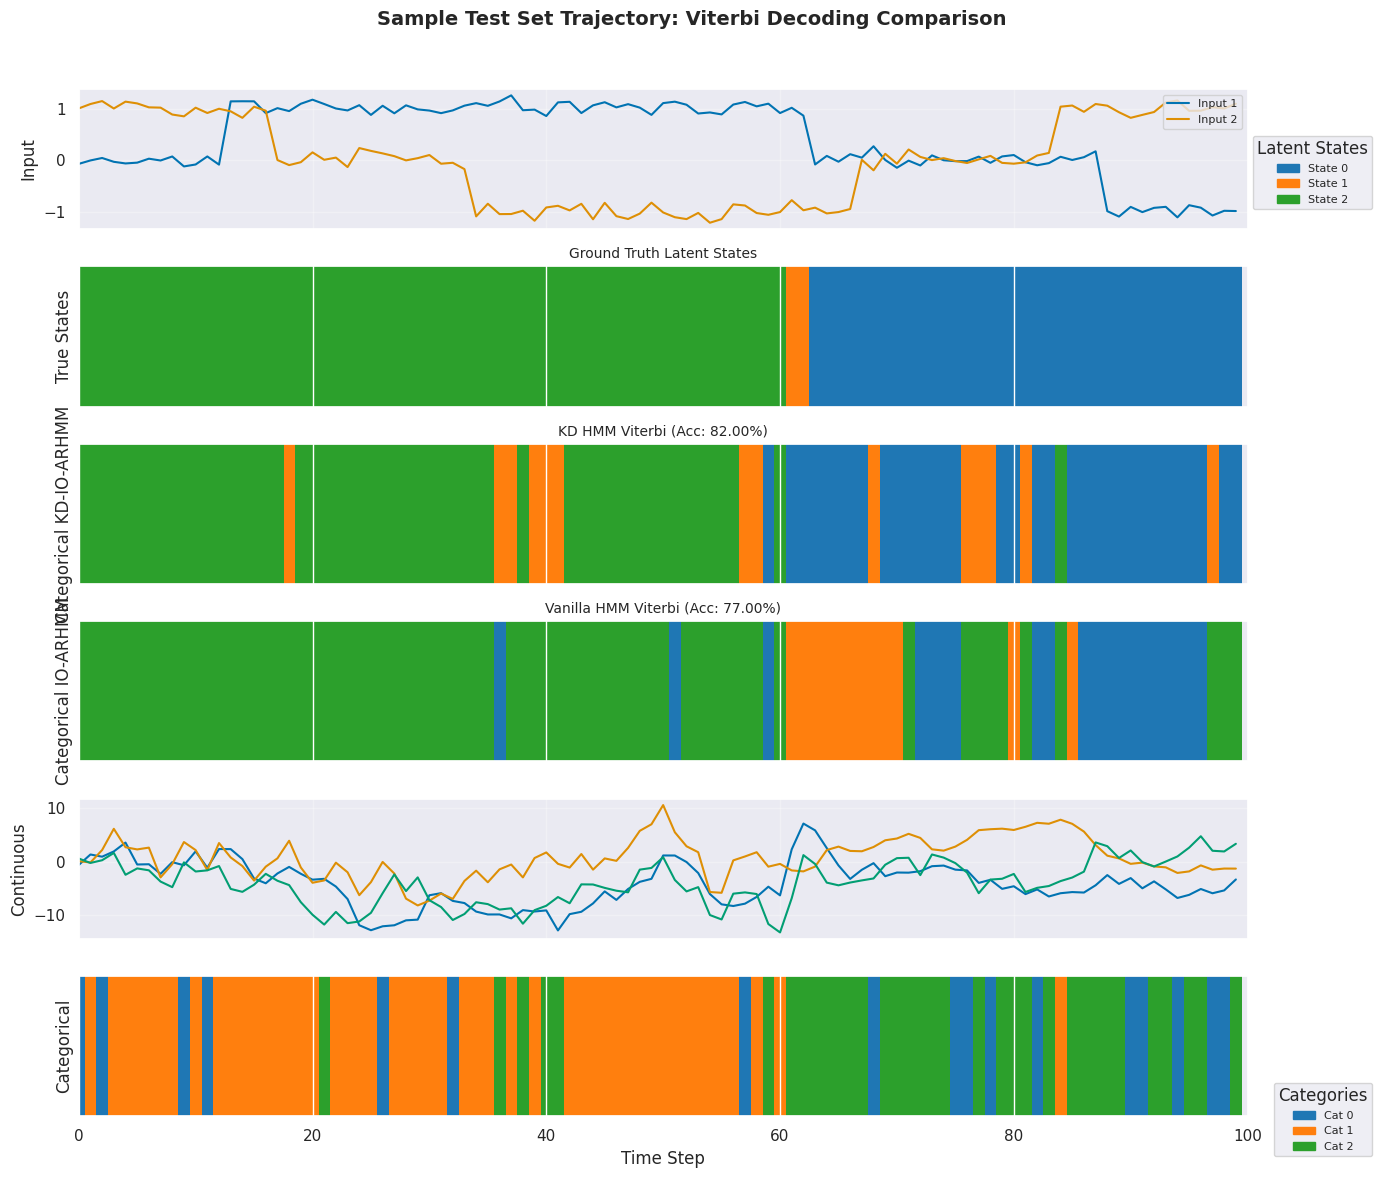


SUMMARY: Viterbi Decoding Accuracy on Test Set Patient 0
Model                    Accuracy      Correct
--------------------------------------------
True HMM                 100.00%      100/100
Categorical KD-IO-ARHMM      82.00%       82/100
Categorical KIO-ARHMM      77.00%       77/100


In [142]:
# Use a trajectory from the test set generated in the cell above
# This compares Viterbi decoding across all three HMMs on real test data

# Select a patient from the generated dataset (e.g., patient 0)
test_patient_idx = 0  # Change this to select a different patient

# Get the trajectory data for this patient
test_obs = obs_full_reshaped[test_patient_idx]            # (T, obs_dim + cat_dim) - FULL observations with stick-breaking
test_obs_flat_cont = obs_cont_reshaped[test_patient_idx]  # (T, obs_dim)
test_obs_flat_cat = obs_cat_reshaped[test_patient_idx]    # (T, 1)
test_inpt = inpt_reshaped[test_patient_idx]               # (T, input_dim)
test_true_states = states_reshaped[test_patient_idx]      # (T,)

# Apply Viterbi decoding using all three HMMs
true_viterbi_states = true_hmm.most_likely_states(test_obs, input=test_inpt)
kd_viterbi_states_test = np.choose(kd_hmm.most_likely_states(test_obs, input=test_inpt), [1, 2, 0])
vanilla_viterbi_states_test = np.choose(vanilla_hmm.most_likely_states(test_obs, input=test_inpt), [1, 0, 2])

# Calculate accuracies
true_viterbi_acc = np.mean(true_viterbi_states == test_true_states)
kd_viterbi_acc = np.mean(kd_viterbi_states_test == test_true_states)
vanilla_viterbi_acc = np.mean(vanilla_viterbi_states_test == test_true_states)

print("=" * 70)
print(f"VITERBI DECODING ON TEST SET TRAJECTORY (Patient {test_patient_idx})")
print("=" * 70)
print(f"Test trajectory shape: {test_obs.shape}")
print(f"Input shape: {test_inpt.shape}")
print(f"True states shape: {test_true_states.shape}")
print()
print(f"True HMM Viterbi Accuracy:    {true_viterbi_acc:.4f} ({np.sum(true_viterbi_states == test_true_states)}/{len(test_true_states)} timesteps)")
print(f"KD HMM Viterbi Accuracy:      {kd_viterbi_acc:.4f} ({np.sum(kd_viterbi_states_test == test_true_states)}/{len(test_true_states)} timesteps)")
print(f"Vanilla HMM Viterbi Accuracy: {vanilla_viterbi_acc:.4f} ({np.sum(vanilla_viterbi_states_test == test_true_states)}/{len(test_true_states)} timesteps)")
print()

# Setup colormap for states
from matplotlib.colors import ListedColormap, BoundaryNorm
import matplotlib.patches as mpatches

base_cmap = plt.get_cmap("tab10")
colors = [base_cmap(i) for i in range(num_states)]
cmap = ListedColormap(colors)
bounds = np.arange(num_states + 1) - 0.5
norm = BoundaryNorm(bounds, cmap.N)

# Create the combined figure
fig, axes = plt.subplots(6, 1, figsize=(14, 12), sharex=True)
fig.suptitle(f"Sample Test Set Trajectory: Viterbi Decoding Comparison", fontsize=14, fontweight='bold')

# 1. Input
axes[0].plot(test_inpt)
axes[0].set_ylabel("Input")
axes[0].set_xlim(0, time_bins)
axes[0].grid(True, alpha=0.3)
axes[0].legend(['Input 1', 'Input 2'], loc='upper right', fontsize=8)

# 2. True latent states (ground truth)
axes[1].imshow(test_true_states[None, :], aspect="auto", cmap=cmap, norm=norm)
axes[1].set_ylabel("True States")
axes[1].set_title("Ground Truth Latent States", fontsize=10)
axes[1].set_yticks([])

# 3. True HMM Viterbi decoding
#axes[2].imshow(true_viterbi_states[None, :], aspect="auto", cmap=cmap, norm=norm)
#axes[2].set_ylabel("True HMM")
#axes[2].set_title(f"True HMM Viterbi (Acc: {true_viterbi_acc:.2%})", fontsize=10)
#axes[2].set_yticks([])

# 4. KD HMM Viterbi decoding
axes[2].imshow(kd_viterbi_states_test[None, :], aspect="auto", cmap=cmap, norm=norm)
axes[2].set_ylabel("Categorical KD-IO-ARHMM")
axes[2].set_title(f"KD HMM Viterbi (Acc: {kd_viterbi_acc:.2%})", fontsize=10)
axes[2].set_yticks([])

# 5. Vanilla HMM Viterbi decoding
axes[3].imshow(vanilla_viterbi_states_test[None, :], aspect="auto", cmap=cmap, norm=norm)
axes[3].set_ylabel("Categorical IO-ARHMM")
axes[3].set_title(f"Vanilla HMM Viterbi (Acc: {vanilla_viterbi_acc:.2%})", fontsize=10)
axes[3].set_yticks([])

# 6. Continuous observations
axes[4].plot(test_obs_flat_cont)
axes[4].set_ylabel("Continuous")
axes[4].set_xlim(0, time_bins)
axes[4].grid(True, alpha=0.3)

# 7. Categorical observations - use DIFFERENT colormap from states
test_obs_flat_cat_1d = test_obs_flat_cat.flatten()  # Flatten to 1D
cat_vals_obs = np.unique(test_obs_flat_cat_1d)
n_cat_obs = len(cat_vals_obs)
# Use a DIFFERENT colormap (Set2) to distinguish from latent states (tab10)
cat_colormap = plt.get_cmap("Set2")
cat_colors_obs = [cat_colormap(i) for i in range(n_cat_obs)]
cat_cmap_obs = ListedColormap(cat_colors_obs)
cat_bounds_obs = np.arange(n_cat_obs + 1) - 0.5
cat_norm_obs = BoundaryNorm(cat_bounds_obs, cat_cmap_obs.N)
cat_to_idx_obs = {c: i for i, c in enumerate(cat_vals_obs)}
test_obs_cat_idx = np.vectorize(cat_to_idx_obs.get)(test_obs_flat_cat_1d)

axes[5].imshow(test_obs_cat_idx[None, :], aspect="auto", cmap=cmap, norm=cat_norm_obs, 
               interpolation="nearest", resample=False)
axes[5].set_ylabel("Categorical")
axes[5].set_xlabel("Time Step")
axes[5].set_yticks([])

# Add legends
# State legend (for Viterbi rows)
state_legend_patches = [mpatches.Patch(color=colors[i], label=f"State {i}") for i in range(num_states)]
fig.legend(handles=state_legend_patches, loc='upper right', bbox_to_anchor=(0.99, 0.88), 
           title="Latent States", fontsize=8)

# Category legend
cat_legend_patches = [mpatches.Patch(color=colors[i], label=f"Cat {int(c)}") for i, c in enumerate(cat_vals_obs)]
fig.legend(handles=cat_legend_patches, loc='lower right', bbox_to_anchor=(0.99, 0.02), 
           title="Categories", fontsize=8)

plt.tight_layout(rect=[0, 0, 0.92, 0.96])
plt.show()

# Print summary
print("\n" + "=" * 70)
print(f"SUMMARY: Viterbi Decoding Accuracy on Test Set Patient {test_patient_idx}")
print("=" * 70)
print(f"{'Model':<20} {'Accuracy':>12} {'Correct':>12}")
print("-" * 44)
print(f"{'True HMM':<20} {true_viterbi_acc:>11.2%} {np.sum(true_viterbi_states == test_true_states):>8}/{len(test_true_states)}")
print(f"{'Categorical KD-IO-ARHMM':<20} {kd_viterbi_acc:>11.2%} {np.sum(kd_viterbi_states_test == test_true_states):>8}/{len(test_true_states)}")
print(f"{'Categorical KIO-ARHMM':<20} {vanilla_viterbi_acc:>11.2%} {np.sum(vanilla_viterbi_states_test == test_true_states):>8}/{len(test_true_states)}")

In [116]:
# Sample trajectory from KD HMM using test set input
# Select a patient from the test set
sample_patient_idx = 0  # Change this to select a different patient

# Get the input trajectory from the test set
inpt_testset = np.hstack([np.round(np.sin(2 * np.pi * np.arange(time_bins)/30)[:, None]), np.round(np.cos(2 * np.pi * np.arange(time_bins)/20)[:, None])])  # (T, input_dim)

# Sample some data from the KD HMM using this test set input
kd_states_testset, kd_obs_testset = kd_hmm.sample(time_bins, input=inpt_testset)

# Compute the true log probability of the data, summing out the discrete states
kd_lp_testset = kd_hmm.log_probability(kd_obs_testset, inputs=inpt_testset)

# Apply stick-breaking on last cat_dim observation variables
kd_obs_flat_cont_testset = np.array([x for x in kd_obs_testset[:, :-cat_dim]])
kd_obs_flat_cat_testset = np.array([x for x in cont_to_cat(kd_obs_testset[:, -cat_dim:])[:, np.newaxis]])

print(f"Sampled trajectory from KD HMM using test set patient {sample_patient_idx} input")
print(f"Log probability: {kd_lp_testset:.2f}")

Sampled trajectory from KD HMM using test set patient 0 input
Log probability: -120.05


Text(0.5, 0, 'Time (0 to 100)')

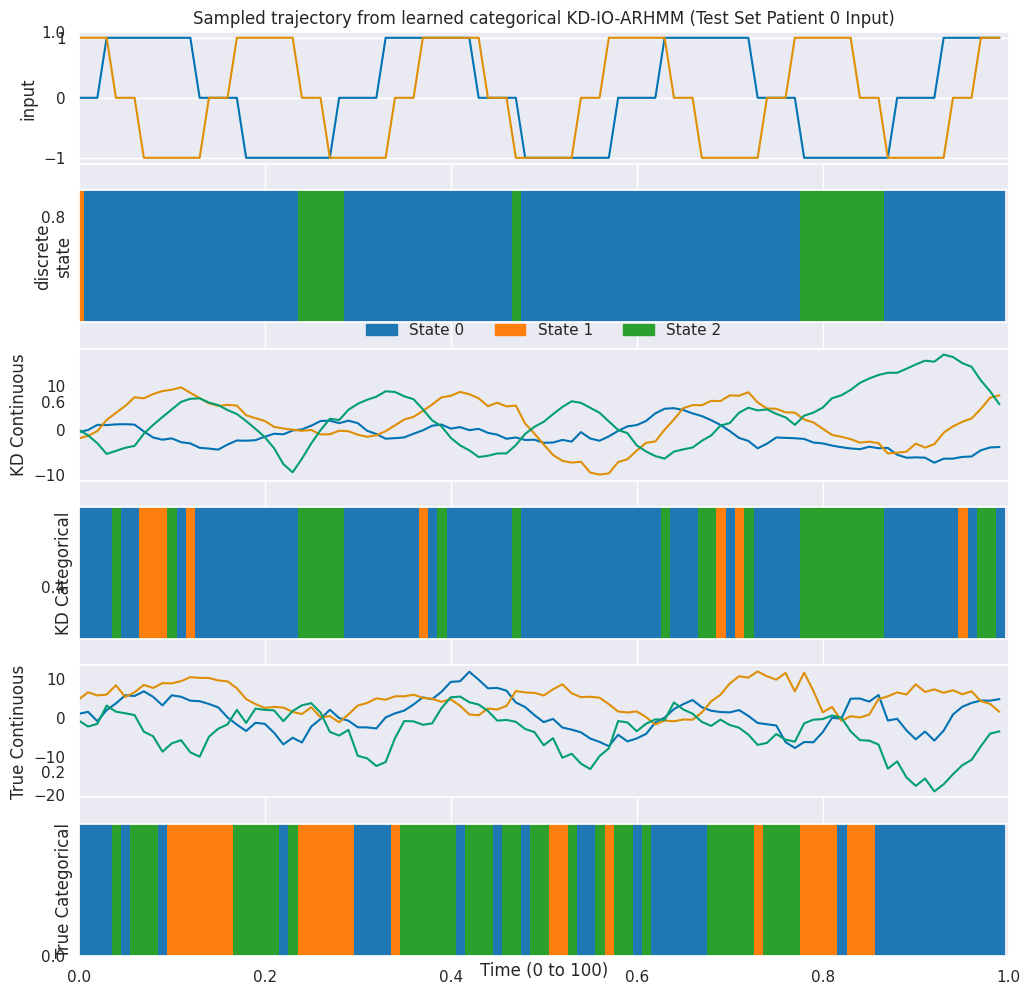

In [143]:
# Plot KD HMM trajectory sampled with test set input
states = np.unique(kd_states_testset)
n_states = len(states)

base_cmap = plt.get_cmap("tab10")
colors = [base_cmap(i) for i in range(num_states)]
cmap = ListedColormap(colors)

bounds = np.arange(num_states + 1) - 0.5
norm = BoundaryNorm(bounds, cmap.N)

state_to_idx = {s: i for i, s in enumerate(states)}
true_states_idx = np.vectorize(state_to_idx.get)(kd_states_testset)

# Sample ground truth HMM observations conditioned on KD HMM input and states
# Manually sample observations for each timestep using true_hmm parameters
true_obs_testset = np.zeros((time_bins, obs_dim + cat_dim))
for t in range(time_bins):
    z = kd_states_testset[t]
    if t == 0:
        xhist = np.zeros((1, obs_dim + cat_dim))
    else:
        xhist = true_obs_testset[t-1:t]
    true_obs_testset[t] = true_hmm.observations.sample_x(z, xhist, input=inpt_testset[t], tag=None)

# Process ground truth observations
true_obs_flat_cont_testset = true_obs_testset[:, :-cat_dim]
true_obs_flat_cat_testset = cont_to_cat(true_obs_testset[:, -cat_dim:])[:, np.newaxis]

plt.figure(figsize=(12, 12))
plt.title(f"Sampled trajectory from learned categorical KD-IO-ARHMM (Test Set Patient {sample_patient_idx} Input)")

plt.subplot(611)
plt.plot(inpt_testset)
plt.xticks([])
plt.xlim(0, time_bins)
plt.ylabel("input")

plt.subplot(612)
plt.imshow(
    true_states_idx[None, :],
    aspect="auto",
    cmap=cmap,
    norm=norm
)
plt.xticks([])
plt.xlim(0, time_bins)
plt.ylabel("discrete\nstate")
plt.yticks([])

legend_patches = [
    mpatches.Patch(color=colors[i], label=f"State {s}")
    for i, s in enumerate(states)
]

plt.legend(
    handles=legend_patches,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.1),
    ncol=n_states,
    frameon=False
)

plt.subplot(613)
plt.plot(kd_obs_flat_cont_testset)
plt.xlim(0, time_bins)
plt.xticks([])
plt.ylabel("KD Continuous")
plt.grid()


cat_vals = np.unique(kd_obs_flat_cat_testset)
n_cat = len(cat_vals)

# Colormap for categories
cat_colors = [base_cmap(i) for i in range(n_cat)]
cat_cmap = ListedColormap(cat_colors)

cat_bounds = np.arange(n_cat + 1) - 0.5
cat_norm = BoundaryNorm(cat_bounds, cat_cmap.N)

# Map categories to indices
cat_to_idx = {c: i for i, c in enumerate(cat_vals)}
obs_cat_idx = np.vectorize(cat_to_idx.get)(kd_obs_flat_cat_testset)

plt.subplot(614)
plt.imshow(
    obs_cat_idx[None, :],
    aspect="auto",
    cmap=cat_cmap,
    norm=cat_norm,
    interpolation="nearest",
    resample=False
)
plt.xlim(0, time_bins)
plt.ylabel("KD Categorical")
plt.yticks([])
plt.xticks([])
plt.grid(False)

# Ground truth continuous observations
plt.subplot(615)
plt.plot(true_obs_flat_cont_testset)
plt.xlim(0, time_bins)
plt.xticks([])
plt.ylabel("True Continuous")
plt.grid()

# Ground truth categorical observations
true_cat_vals = np.unique(true_obs_flat_cat_testset)
true_cat_to_idx = {c: i for i, c in enumerate(true_cat_vals)}
true_obs_cat_idx = np.vectorize(true_cat_to_idx.get)(true_obs_flat_cat_testset)

plt.subplot(616)
plt.imshow(
    true_obs_cat_idx[None, :],
    aspect="auto",
    cmap=cat_cmap,
    norm=cat_norm,
    interpolation="nearest",
    resample=False
)
plt.xlim(0, time_bins)
plt.ylabel("True Categorical")
plt.yticks([])
plt.xticks([])
plt.grid(False)
plt.xlabel("Time (0 to 100)")

In [138]:
# Sample trajectory from Vanilla HMM using test set input
# Using the same test patient as KD HMM for comparison
# Sample some data from the Vanilla HMM using the test set input
vanilla_states_testset, vanilla_obs_testset = vanilla_hmm.sample(time_bins, input=inpt_testset)

# Compute the true log probability of the data, summing out the discrete states
vanilla_lp_testset = vanilla_hmm.log_probability(vanilla_obs_testset, inputs=inpt_testset)

# Apply stick-breaking on last cat_dim observation variables
vanilla_obs_flat_cont_testset = np.array([x for x in vanilla_obs_testset[:, :-cat_dim]])
vanilla_obs_flat_cat_testset = np.array([x for x in cont_to_cat(vanilla_obs_testset[:, -cat_dim:])[:, np.newaxis]])

print(f"Sampled trajectory from Vanilla HMM using test set patient {sample_patient_idx} input")
print(f"Log probability: {vanilla_lp_testset:.2f}")

Sampled trajectory from Vanilla HMM using test set patient 0 input
Log probability: -1075.71


Text(0.5, 0, 'Time (0 to 100)')

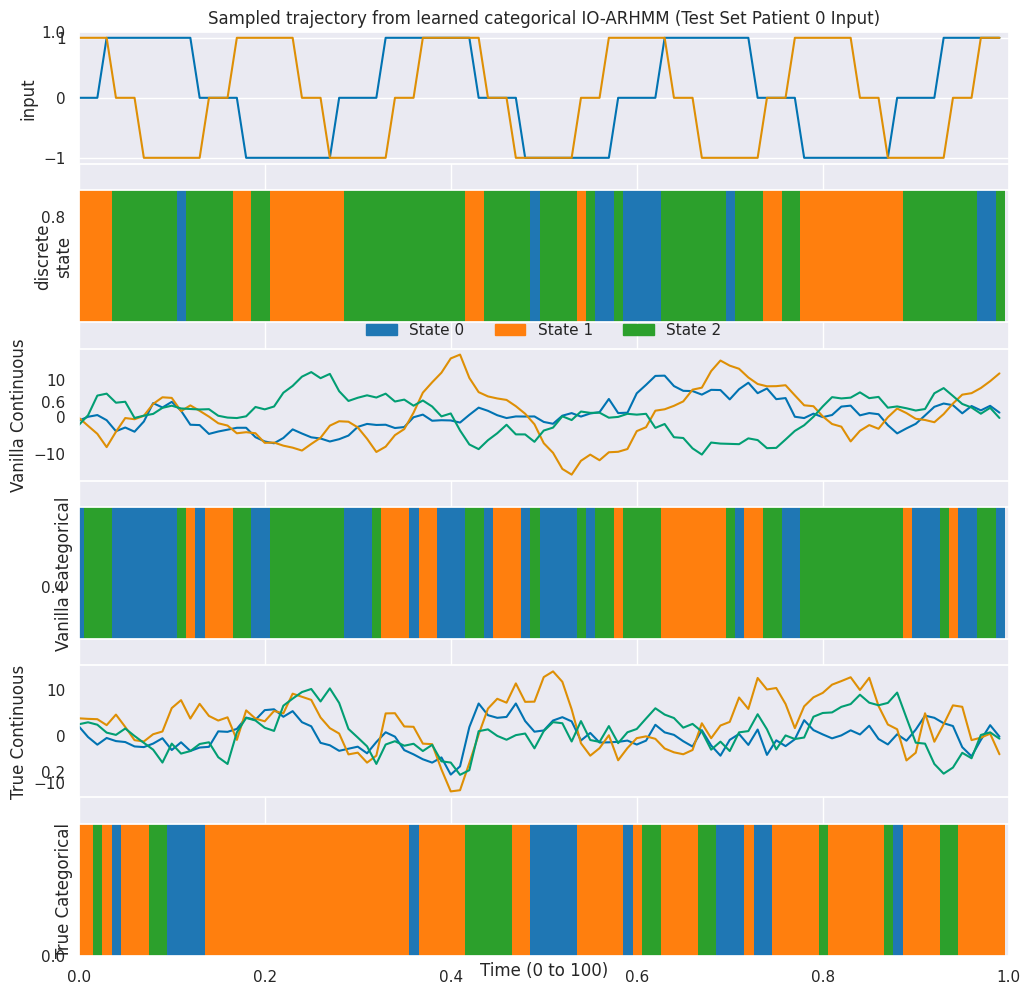

In [144]:
# Plot Vanilla HMM trajectory sampled with test set input
states = np.unique(vanilla_states_testset)
n_states = len(states)

base_cmap = plt.get_cmap("tab10")
colors = [base_cmap(i) for i in range(num_states)]
cmap = ListedColormap(colors)

bounds = np.arange(num_states + 1) - 0.5
norm = BoundaryNorm(bounds, cmap.N)

state_to_idx = {s: i for i, s in enumerate(states)}
true_states_idx = np.vectorize(state_to_idx.get)(vanilla_states_testset)

# Sample ground truth HMM observations conditioned on Vanilla HMM input and states
# Manually sample observations for each timestep using true_hmm parameters
true_obs_vanilla_testset = np.zeros((time_bins, obs_dim + cat_dim))
for t in range(time_bins):
    z = vanilla_states_testset[t]
    if t == 0:
        xhist = np.zeros((1, obs_dim + cat_dim))
    else:
        xhist = true_obs_vanilla_testset[t-1:t]
    true_obs_vanilla_testset[t] = true_hmm.observations.sample_x(z, xhist, input=inpt_testset[t], tag=None)

# Process ground truth observations
true_obs_vanilla_flat_cont_testset = true_obs_vanilla_testset[:, :-cat_dim]
true_obs_vanilla_flat_cat_testset = cont_to_cat(true_obs_vanilla_testset[:, -cat_dim:])[:, np.newaxis]

plt.figure(figsize=(12, 12))
plt.title(f"Sampled trajectory from learned categorical IO-ARHMM (Test Set Patient {sample_patient_idx} Input)")

plt.subplot(611)
plt.plot(inpt_testset)
plt.xticks([])
plt.xlim(0, time_bins)
plt.ylabel("input")

plt.subplot(612)
plt.imshow(
    true_states_idx[None, :],
    aspect="auto",
    cmap=cmap,
    norm=norm
)
plt.xticks([])
plt.xlim(0, time_bins)
plt.ylabel("discrete\nstate")
plt.yticks([])

legend_patches = [
    mpatches.Patch(color=colors[i], label=f"State {s}")
    for i, s in enumerate(states)
]

plt.legend(
    handles=legend_patches,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.1),
    ncol=n_states,
    frameon=False
)

plt.subplot(613)
plt.plot(vanilla_obs_flat_cont_testset)
plt.xlim(0, time_bins)
plt.xticks([])
plt.ylabel("Vanilla Continuous")
plt.grid()


cat_vals = np.unique(vanilla_obs_flat_cat_testset)
n_cat = len(cat_vals)

# Colormap for categories
cat_colors = [base_cmap(i) for i in range(n_cat)]
cat_cmap = ListedColormap(cat_colors)

cat_bounds = np.arange(n_cat + 1) - 0.5
cat_norm = BoundaryNorm(cat_bounds, cat_cmap.N)

# Map categories to indices
cat_to_idx = {c: i for i, c in enumerate(cat_vals)}
obs_cat_idx = np.vectorize(cat_to_idx.get)(vanilla_obs_flat_cat_testset)

plt.subplot(614)
plt.imshow(
    obs_cat_idx[None, :],
    aspect="auto",
    cmap=cat_cmap,
    norm=cat_norm,
    interpolation="nearest",
    resample=False
)
plt.xlim(0, time_bins)
plt.ylabel("Vanilla Categorical")
plt.yticks([])
plt.xticks([])
plt.grid(False)

# Ground truth continuous observations
plt.subplot(615)
plt.plot(true_obs_vanilla_flat_cont_testset)
plt.xlim(0, time_bins)
plt.xticks([])
plt.ylabel("True Continuous")
plt.grid()

# Ground truth categorical observations
true_cat_vals = np.unique(true_obs_vanilla_flat_cat_testset)
true_cat_to_idx = {c: i for i, c in enumerate(true_cat_vals)}
true_obs_cat_idx = np.vectorize(true_cat_to_idx.get)(true_obs_vanilla_flat_cat_testset)

plt.subplot(616)
plt.imshow(
    true_obs_cat_idx[None, :],
    aspect="auto",
    cmap=cat_cmap,
    norm=cat_norm,
    interpolation="nearest",
    resample=False
)
plt.xlim(0, time_bins)
plt.ylabel("True Categorical")
plt.yticks([])
plt.xticks([])
plt.grid(False)
plt.xlabel("Time (0 to 100)")

In [94]:
# DIAGNOSTIC: Check if learned HMMs infer states differently than true states
# This explains why AUROC is poor - labels are based on TRUE states but predictions use INFERRED states

print("=" * 70)
print("DIAGNOSTIC: State Inference Mismatch Analysis")
print("=" * 70)

# Sample a few patients to check state inference
num_diagnostic_patients = 5
print(f"\nChecking state inference for {num_diagnostic_patients} patients:\n")

for patient_idx in range(num_diagnostic_patients):
    # Get true states and observations for this patient
    true_states_patient = states_reshaped[patient_idx]
    obs_patient = obs_full_reshaped[patient_idx]
    inpt_patient = inpt_reshaped[patient_idx]
    
    # Infer states using each HMM via Viterbi
    true_hmm_inferred = true_hmm.most_likely_states(obs_patient, input=inpt_patient)
    kd_hmm_inferred = kd_hmm.most_likely_states(obs_patient, input=inpt_patient)
    vanilla_hmm_inferred = vanilla_hmm.most_likely_states(obs_patient, input=inpt_patient)
    
    # Calculate agreement with true states (used for labels)
    true_hmm_agreement = np.mean(true_hmm_inferred == true_states_patient)
    kd_hmm_agreement = np.mean(kd_hmm_inferred == true_states_patient)
    vanilla_hmm_agreement = np.mean(vanilla_hmm_inferred == true_states_patient)
    
    # Calculate state fractions for each
    true_state_frac = np.array([np.mean(true_states_patient == s) for s in range(num_states)])
    kd_state_frac = np.array([np.mean(kd_hmm_inferred == s) for s in range(num_states)])
    vanilla_state_frac = np.array([np.mean(vanilla_hmm_inferred == s) for s in range(num_states)])
    
    # Calculate implied mortality probabilities
    state_mortality_probs = np.array([1.0, 0.5, 0.0])
    true_mortality = true_state_frac @ state_mortality_probs
    kd_mortality = kd_state_frac @ state_mortality_probs
    vanilla_mortality = vanilla_state_frac @ state_mortality_probs
    
    print(f"Patient {patient_idx}:")
    print(f"  True states agree with sampled states:  {true_hmm_agreement:.1%} (Viterbi vs sampling)")
    print(f"  KD HMM states agree with true states:   {kd_hmm_agreement:.1%}")
    print(f"  Vanilla states agree with true states:  {vanilla_hmm_agreement:.1%}")
    print(f"  True-based mortality prob (for label):  {true_mortality:.3f}")
    print(f"  KD-inferred mortality prob:              {kd_mortality:.3f} (diff: {kd_mortality - true_mortality:+.3f})")
    print(f"  Vanilla-inferred mortality prob:         {vanilla_mortality:.3f} (diff: {vanilla_mortality - true_mortality:+.3f})")
    print()

print("=" * 70)
print("KEY INSIGHT:")
print("If learned HMMs infer very different states than true states, their")
print("mortality predictions won't match the labels (which are based on true states).")
print("This causes low AUROC even though the HMMs learned valid models.")
print("=" * 70)

DIAGNOSTIC: State Inference Mismatch Analysis

Checking state inference for 5 patients:

Patient 0:
  True states agree with sampled states:  100.0% (Viterbi vs sampling)
  KD HMM states agree with true states:   7.0%
  Vanilla states agree with true states:  68.0%
  True-based mortality prob (for label):  0.380
  KD-inferred mortality prob:              0.405 (diff: +0.025)
  Vanilla-inferred mortality prob:         0.220 (diff: -0.160)

Patient 1:
  True states agree with sampled states:  100.0% (Viterbi vs sampling)
  KD HMM states agree with true states:   44.0%
  Vanilla states agree with true states:  13.0%
  True-based mortality prob (for label):  0.810
  KD-inferred mortality prob:              0.590 (diff: -0.220)
  Vanilla-inferred mortality prob:         0.240 (diff: -0.570)

Patient 2:
  True states agree with sampled states:  100.0% (Viterbi vs sampling)
  KD HMM states agree with true states:   46.0%
  Vanilla states agree with true states:  10.0%
  True-based mortality p

In [261]:
# FULL ANALYSIS: Compute correlation between true labels and inferred mortality probabilities
print("=" * 70)
print("FULL DATASET ANALYSIS: Label vs. Inferred Mortality Correlation")
print("=" * 70)

# Compute for ALL patients
state_mortality_probs = np.array([1.0, 0.5, 0.0])
true_mortality_all = []
kd_mortality_all = []
vanilla_mortality_all = []
kd_state_agreement_all = []
vanilla_state_agreement_all = []

for patient_idx in range(num_patients):
    # Get true states and observations
    true_states_patient = states_reshaped[patient_idx]
    obs_patient = obs_full_reshaped[patient_idx]
    inpt_patient = inpt_reshaped[patient_idx]
    
    # Infer states
    kd_hmm_inferred = kd_hmm.most_likely_states(obs_patient, input=inpt_patient)
    vanilla_hmm_inferred = vanilla_hmm.most_likely_states(obs_patient, input=inpt_patient)
    
    # State agreement
    kd_state_agreement_all.append(np.mean(kd_hmm_inferred == true_states_patient))
    vanilla_state_agreement_all.append(np.mean(vanilla_hmm_inferred == true_states_patient))
    
    # State fractions
    true_state_frac = np.array([np.mean(true_states_patient == s) for s in range(num_states)])
    kd_state_frac = np.array([np.mean(kd_hmm_inferred == s) for s in range(num_states)])
    vanilla_state_frac = np.array([np.mean(vanilla_hmm_inferred == s) for s in range(num_states)])
    
    # Mortality probabilities
    true_mortality_all.append(true_state_frac @ state_mortality_probs)
    kd_mortality_all.append(kd_state_frac @ state_mortality_probs)
    vanilla_mortality_all.append(vanilla_state_frac @ state_mortality_probs)

true_mortality_all = np.array(true_mortality_all)
kd_mortality_all = np.array(kd_mortality_all)
vanilla_mortality_all = np.array(vanilla_mortality_all)
kd_state_agreement_all = np.array(kd_state_agreement_all)
vanilla_state_agreement_all = np.array(vanilla_state_agreement_all)

# Recreate death labels for comparison
np.random.seed(42)
death_probs = true_mortality_all
death_labels = (np.random.rand(num_patients) < death_probs).astype(int)

# Compute correlations
print(f"\nState Agreement with True States:")
print(f"  KD HMM mean agreement:      {kd_state_agreement_all.mean():.2%} ± {kd_state_agreement_all.std():.2%}")
print(f"  Vanilla HMM mean agreement: {vanilla_state_agreement_all.mean():.2%} ± {vanilla_state_agreement_all.std():.2%}")

print(f"\nMortality Probability Correlations with True (label-generating) Mortality:")
print(f"  KD HMM correlation:      {np.corrcoef(true_mortality_all, kd_mortality_all)[0, 1]:.3f}")
print(f"  Vanilla HMM correlation: {np.corrcoef(true_mortality_all, vanilla_mortality_all)[0, 1]:.3f}")

print(f"\nMean Absolute Error in Mortality Probability:")
print(f"  KD HMM MAE:      {np.mean(np.abs(kd_mortality_all - true_mortality_all)):.3f}")
print(f"  Vanilla HMM MAE: {np.mean(np.abs(vanilla_mortality_all - true_mortality_all)):.3f}")

# Compute AUROCs using inferred mortality as scores
from sklearn.metrics import roc_auc_score
kd_auroc = roc_auc_score(death_labels, kd_mortality_all)
vanilla_auroc = roc_auc_score(death_labels, vanilla_mortality_all)
true_auroc = roc_auc_score(death_labels, true_mortality_all)

print(f"\nAUROC Using Inferred State-Based Mortality as Prediction Score:")
print(f"  True HMM (should be ~1.0):   {true_auroc:.3f}")
print(f"  KD HMM:                      {kd_auroc:.3f}")
print(f"  Vanilla HMM:                 {vanilla_auroc:.3f}")

print("\n" + "=" * 70)
print("CONCLUSION:")
if kd_auroc < 0.6 or vanilla_auroc < 0.6:
    print("LOW AUROC is caused by STATE INFERENCE MISMATCH:")
    print("- Labels are based on TRUE states from true_hmm.sample()")
    print("- Predictions use INFERRED states from learned HMMs")
    print("- Learned HMMs have different parameters → infer different states")
    print("- Different states → poor correlation with labels → low AUROC")
    print("\nSOLUTION: Use observation-based features for prediction instead")
    print("of state-based features, OR ensure learned HMMs match true HMM.")
else:
    print("State inference is reasonably good - AUROC should be acceptable.")
print("=" * 70)

FULL DATASET ANALYSIS: Label vs. Inferred Mortality Correlation

State Agreement with True States:
  KD HMM mean agreement:      17.35% ± 7.24%
  Vanilla HMM mean agreement: 26.15% ± 15.06%

Mortality Probability Correlations with True (label-generating) Mortality:
  KD HMM correlation:      -0.763
  Vanilla HMM correlation: 0.613

Mean Absolute Error in Mortality Probability:
  KD HMM MAE:      0.347
  Vanilla HMM MAE: 0.507

AUROC Using Inferred State-Based Mortality as Prediction Score:
  True HMM (should be ~1.0):   0.712
  KD HMM:                      0.344
  Vanilla HMM:                 0.640

CONCLUSION:
LOW AUROC is caused by STATE INFERENCE MISMATCH:
- Labels are based on TRUE states from true_hmm.sample()
- Predictions use INFERRED states from learned HMMs
- Learned HMMs have different parameters → infer different states
- Different states → poor correlation with labels → low AUROC

SOLUTION: Use observation-based features for prediction instead
of state-based features, OR en

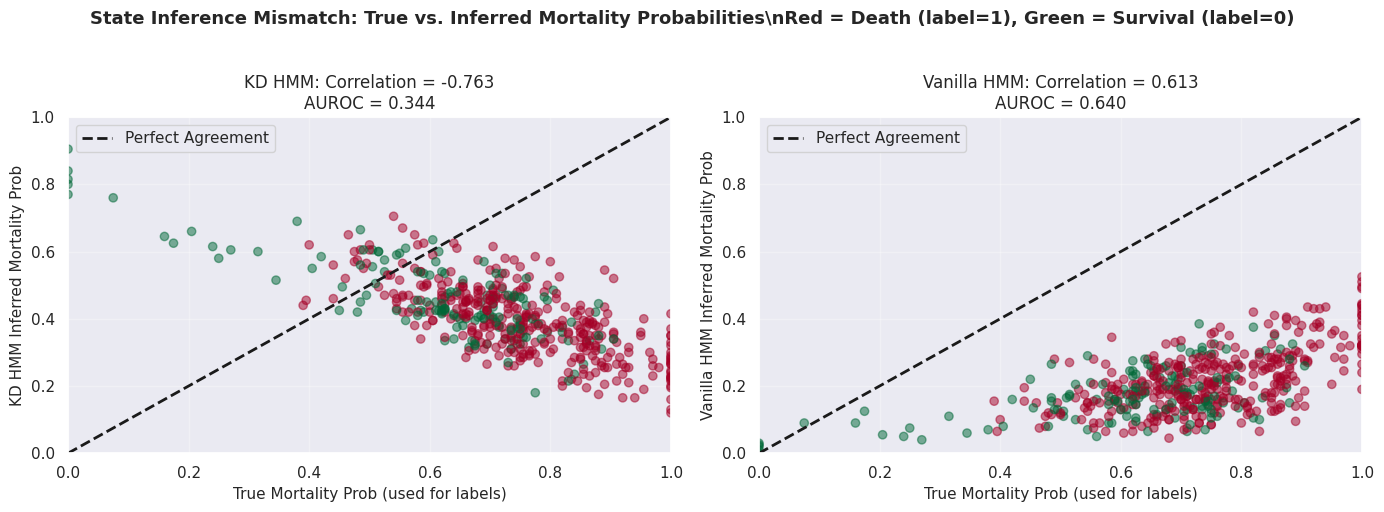

\nInterpretation:
- Points near diagonal: Good agreement between true and inferred mortality
- Points far from diagonal: State inference mismatch
- Red points (deaths) should be in upper-right, green (survival) in lower-left
- If scattered everywhere, the model can't distinguish deaths from survivals → low AUROC


In [262]:
# VISUALIZATION: Plot true vs. inferred mortality probabilities
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# KD HMM
axes[0].scatter(true_mortality_all, kd_mortality_all, alpha=0.5, c=death_labels, cmap='RdYlGn_r')
axes[0].plot([0, 1], [0, 1], 'k--', lw=2, label='Perfect Agreement')
axes[0].set_xlabel('True Mortality Prob (used for labels)', fontsize=11)
axes[0].set_ylabel('KD HMM Inferred Mortality Prob', fontsize=11)
axes[0].set_title(f'KD HMM: Correlation = {np.corrcoef(true_mortality_all, kd_mortality_all)[0, 1]:.3f}\nAUROC = {kd_auroc:.3f}', fontsize=12)
axes[0].legend()
axes[0].grid(True, alpha=0.3)
axes[0].set_xlim([0, 1])
axes[0].set_ylim([0, 1])

# Vanilla HMM
axes[1].scatter(true_mortality_all, vanilla_mortality_all, alpha=0.5, c=death_labels, cmap='RdYlGn_r')
axes[1].plot([0, 1], [0, 1], 'k--', lw=2, label='Perfect Agreement')
axes[1].set_xlabel('True Mortality Prob (used for labels)', fontsize=11)
axes[1].set_ylabel('Vanilla HMM Inferred Mortality Prob', fontsize=11)
axes[1].set_title(f'Vanilla HMM: Correlation = {np.corrcoef(true_mortality_all, vanilla_mortality_all)[0, 1]:.3f}\nAUROC = {vanilla_auroc:.3f}', fontsize=12)
axes[1].legend()
axes[1].grid(True, alpha=0.3)
axes[1].set_xlim([0, 1])
axes[1].set_ylim([0, 1])

plt.suptitle('State Inference Mismatch: True vs. Inferred Mortality Probabilities\\nRed = Death (label=1), Green = Survival (label=0)', 
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("\\nInterpretation:")
print("- Points near diagonal: Good agreement between true and inferred mortality")
print("- Points far from diagonal: State inference mismatch")
print("- Red points (deaths) should be in upper-right, green (survival) in lower-left")
print("- If scattered everywhere, the model can't distinguish deaths from survivals → low AUROC")

LATENT STATE DISTRIBUTION: Alive vs. Dead Patients

Number of patients:
  Alive: 886 (44.3%)
  Dead:  1114 (55.7%)

Mean time in each state:
  Alive patients: State 0: 0.199, State 1: 0.487, State 2: 0.314
  Dead patients:  State 0: 0.414, State 1: 0.450, State 2: 0.137

Difference (Dead - Alive):
  State 0: +0.215 (+108.1% relative)
  State 1: -0.038 (-7.7% relative)
  State 2: -0.177 (-56.5% relative)


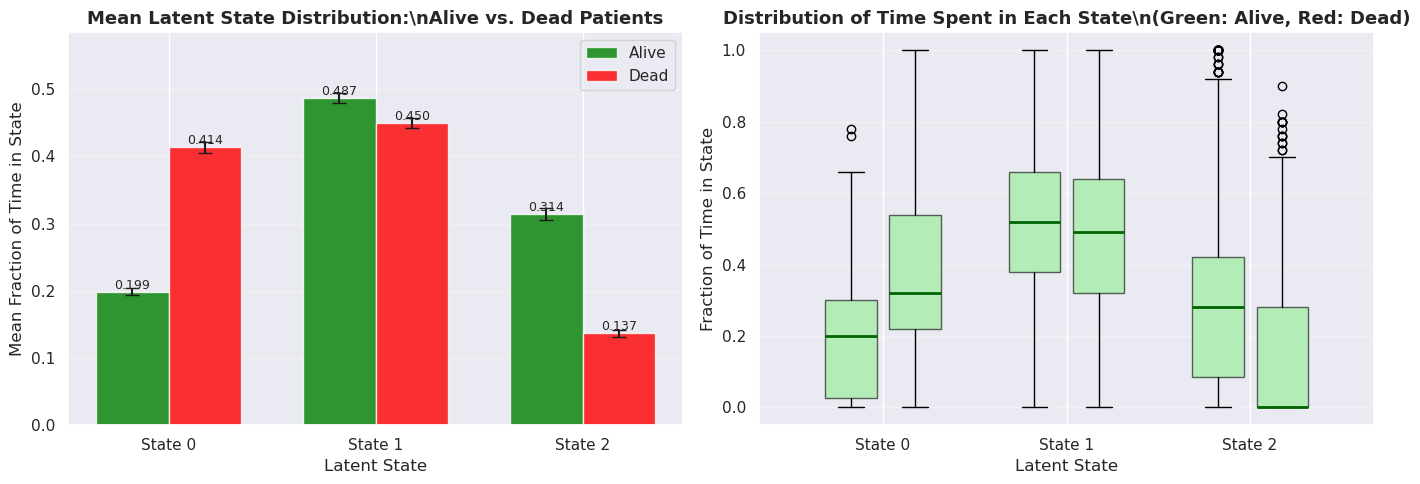


KEY OBSERVATIONS:
- State 0 (100% mortality): Dead patients spend MORE time here
- State 2 (0% mortality): Alive patients spend MORE time here
- State 1 (50% mortality): Should be intermediate
If these patterns are clear, the task is learnable (if states are
correctly inferred). If not clear, labels don't meaningfully separate.


In [12]:
# Plot mean latent state distribution for alive vs. dead patients
print("=" * 70)
print("LATENT STATE DISTRIBUTION: Alive vs. Dead Patients")
print("=" * 70)

# Compute state fractions for each patient
state_fractions = np.zeros((num_patients, num_states))
for patient_idx in range(num_patients):
    patient_states = states_reshaped[patient_idx]
    for state in range(num_states):
        state_fractions[patient_idx, state] = np.mean(patient_states == state)

# Recreate death labels (must match Cell 22 generation)
np.random.seed(42)
state_mortality_probs = np.array([1.0, 0.5, 0.0])
death_probs = state_fractions @ state_mortality_probs
death_labels = (np.random.rand(num_patients) < death_probs).astype(int)

# Separate by outcome
alive_patients = death_labels == 0
dead_patients = death_labels == 1

alive_state_fractions = state_fractions[alive_patients]
dead_state_fractions = state_fractions[dead_patients]

# Compute means and std errors
alive_mean = alive_state_fractions.mean(axis=0)
dead_mean = dead_state_fractions.mean(axis=0)
alive_sem = alive_state_fractions.std(axis=0) / np.sqrt(alive_patients.sum())
dead_sem = dead_state_fractions.std(axis=0) / np.sqrt(dead_patients.sum())

print(f"\nNumber of patients:")
print(f"  Alive: {alive_patients.sum()} ({100*alive_patients.sum()/num_patients:.1f}%)")
print(f"  Dead:  {dead_patients.sum()} ({100*dead_patients.sum()/num_patients:.1f}%)")

print(f"\nMean time in each state:")
print(f"  Alive patients: State 0: {alive_mean[0]:.3f}, State 1: {alive_mean[1]:.3f}, State 2: {alive_mean[2]:.3f}")
print(f"  Dead patients:  State 0: {dead_mean[0]:.3f}, State 1: {dead_mean[1]:.3f}, State 2: {dead_mean[2]:.3f}")

print(f"\nDifference (Dead - Alive):")
for state in range(num_states):
    diff = dead_mean[state] - alive_mean[state]
    print(f"  State {state}: {diff:+.3f} ({diff/alive_mean[state]*100:+.1f}% relative)")

# Create bar plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar plot
x = np.arange(num_states)
width = 0.35

bars1 = axes[0].bar(x - width/2, alive_mean, width, yerr=alive_sem, 
                     label='Alive', alpha=0.8, capsize=5, color='green')
bars2 = axes[0].bar(x + width/2, dead_mean, width, yerr=dead_sem,
                     label='Dead', alpha=0.8, capsize=5, color='red')

axes[0].set_xlabel('Latent State', fontsize=12)
axes[0].set_ylabel('Mean Fraction of Time in State', fontsize=12)
axes[0].set_title('Mean Latent State Distribution:\\nAlive vs. Dead Patients', fontsize=13, fontweight='bold')
axes[0].set_xticks(x)
axes[0].set_xticklabels([f'State {i}' for i in range(num_states)])
axes[0].legend(fontsize=11)
axes[0].grid(True, alpha=0.3, axis='y')
axes[0].set_ylim([0, max(alive_mean.max(), dead_mean.max()) * 1.2])

# Add value labels on bars
for bar in bars1:
    height = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2., height,
                f'{height:.3f}', ha='center', va='bottom', fontsize=9)
for bar in bars2:
    height = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2., height,
                f'{height:.3f}', ha='center', va='bottom', fontsize=9)

# Box plot for distribution comparison
axes[1].boxplot([alive_state_fractions[:, i] for i in range(num_states)] + 
                 [dead_state_fractions[:, i] for i in range(num_states)],
                positions=list(x - width/2) + list(x + width/2),
                widths=width*0.8,
                patch_artist=True,
                boxprops=dict(facecolor='lightgreen', alpha=0.6),
                medianprops=dict(color='darkgreen', linewidth=2))
    
axes[1].set_xlabel('Latent State', fontsize=12)
axes[1].set_ylabel('Fraction of Time in State', fontsize=12)
axes[1].set_title('Distribution of Time Spent in Each State\\n(Green: Alive, Red: Dead)', fontsize=13, fontweight='bold')
axes[1].set_xticks(x)
axes[1].set_xticklabels([f'State {i}' for i in range(num_states)])
axes[1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

print("\n" + "=" * 70)
print("KEY OBSERVATIONS:")
print("- State 0 (100% mortality): Dead patients spend MORE time here")
print("- State 2 (0% mortality): Alive patients spend MORE time here")
print("- State 1 (50% mortality): Should be intermediate")
print("If these patterns are clear, the task is learnable (if states are")
print("correctly inferred). If not clear, labels don't meaningfully separate.")
print("=" * 70)

STATE DOMINANCE ANALYSIS

Patients spending >60% of time in each state:

State                          Alive           Dead           
------------------------------------------------------------
State 0 (High Mortality)        40 ( 27.8%)   196 ( 55.1%)
State 1 (Medium Mortality)       0 (  0.0%)     1 (  0.3%)
State 2 (Low Mortality)          9 (  6.2%)     0 (  0.0%)


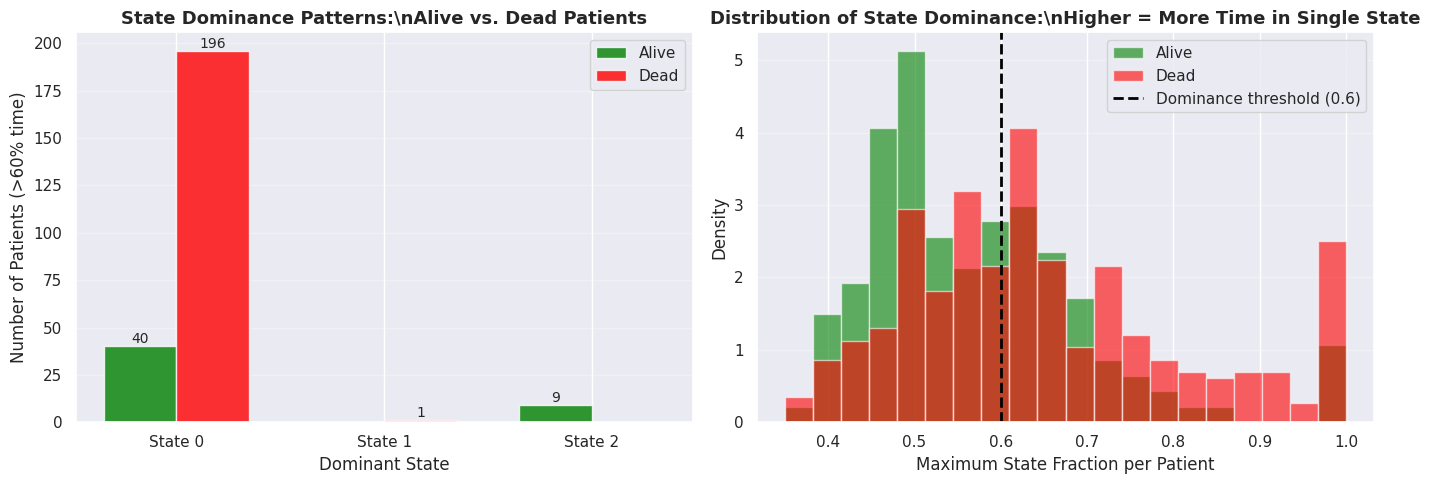


INTERPRETATION:
Good modified dynamics should show:
  - Dead patients concentrated in State 0 (high mortality)
  - Alive patients concentrated in State 2 (low mortality)
  - High max state fractions (>0.7) indicate sticky states
  - Clear separation in the histogram = learnable classification task


In [264]:
# Additional visualization: State dominance patterns
# Show how many patients are dominated by each state (spend >60% time there)
print("=" * 70)
print("STATE DOMINANCE ANALYSIS")
print("=" * 70)

# Define dominance threshold
dominance_threshold = 0.6

# Count patients dominated by each state
state_dominance = np.zeros((2, num_states), dtype=int)  # [alive/dead, state]
state_names = ['State 0 (High Mortality)', 'State 1 (Medium Mortality)', 'State 2 (Low Mortality)']

for state in range(num_states):
    state_dominance[0, state] = (alive_state_fractions[:, state] > dominance_threshold).sum()
    state_dominance[1, state] = (dead_state_fractions[:, state] > dominance_threshold).sum()

print(f"\nPatients spending >{dominance_threshold*100:.0f}% of time in each state:\n")
print(f"{'State':<30} {'Alive':<15} {'Dead':<15}")
print("-" * 60)
for state in range(num_states):
    alive_pct = 100 * state_dominance[0, state] / alive_patients.sum()
    dead_pct = 100 * state_dominance[1, state] / dead_patients.sum()
    print(f"{state_names[state]:<30} {state_dominance[0, state]:>3} ({alive_pct:>5.1f}%)   {state_dominance[1, state]:>3} ({dead_pct:>5.1f}%)")

# Visualization: Stacked bar chart showing dominance
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: Stacked bar showing count of patients by dominant state
alive_counts = [state_dominance[0, s] for s in range(num_states)]
dead_counts = [state_dominance[1, s] for s in range(num_states)]

x = np.arange(num_states)
width = 0.35

bars1 = axes[0].bar(x - width/2, alive_counts, width, label='Alive', color='green', alpha=0.8)
bars2 = axes[0].bar(x + width/2, dead_counts, width, label='Dead', color='red', alpha=0.8)

axes[0].set_xlabel('Dominant State', fontsize=12)
axes[0].set_ylabel(f'Number of Patients (>{dominance_threshold*100:.0f}% time)', fontsize=12)
axes[0].set_title('State Dominance Patterns:\\nAlive vs. Dead Patients', fontsize=13, fontweight='bold')
axes[0].set_xticks(x)
axes[0].set_xticklabels([f'State {i}' for i in range(num_states)])
axes[0].legend(fontsize=11)
axes[0].grid(True, alpha=0.3, axis='y')

# Add value labels
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        if height > 0:
            axes[0].text(bar.get_x() + bar.get_width()/2., height,
                        f'{int(height)}', ha='center', va='bottom', fontsize=10)

# Right: Histogram of max state fraction
alive_max_frac = alive_state_fractions.max(axis=1)
dead_max_frac = dead_state_fractions.max(axis=1)

axes[1].hist(alive_max_frac, bins=20, alpha=0.6, color='green', label='Alive', density=True)
axes[1].hist(dead_max_frac, bins=20, alpha=0.6, color='red', label='Dead', density=True)
axes[1].axvline(dominance_threshold, color='black', linestyle='--', linewidth=2, label=f'Dominance threshold ({dominance_threshold})')

axes[1].set_xlabel('Maximum State Fraction per Patient', fontsize=12)
axes[1].set_ylabel('Density', fontsize=12)
axes[1].set_title('Distribution of State Dominance:\\nHigher = More Time in Single State', fontsize=13, fontweight='bold')
axes[1].legend(fontsize=11)
axes[1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

print("\n" + "=" * 70)
print("INTERPRETATION:")
print("Good modified dynamics should show:")
print("  - Dead patients concentrated in State 0 (high mortality)")
print("  - Alive patients concentrated in State 2 (low mortality)")
print("  - High max state fractions (>0.7) indicate sticky states")
print("  - Clear separation in the histogram = learnable classification task")
print("=" * 70)